# Y a-t-il une corrélation entre la popularité et la complexité d'un jeu de société ?

*Projet de statistique — Cédric Van Gheluwe — Nicolas Ponchaut — Guillaume Delsalle*

**Sommaire**

0. Préparation technique
1. Introduction
2. Présentation du jeu de données
3. Qualité des données
4. Définition de la popularité
5. Analyse exploratoire
6. Application des outils statistiques
7. Interprétation et conclusion
8. Sources

## 0. Préparation technique

### Importation des bibliothèques, définition des constantes et les styles des graphiques. 

In [226]:
#! Versions des paquets utilisés
import sys

import matplotlib
import matplotlib.pyplot as pyplot
import numpy as np
import pandas as pd
import scipy
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

print("python     :", sys.version.split(' ')[0])
for module in (matplotlib, np, pd, scipy):
    print(f"{module.__name__:<11}:", module.__version__)

python     : 3.15.2
matplotlib : 3.11.2
numpy      : 2.5.5
pandas     : 3.1.1
scipy      : 1.18.1


In [227]:
#! definition des constantes
# --- Fichiers de données ---------------------------------------------------
CSV_RAW = "boardGamesRaw.csv"      # bg_info.csv (Kaggle), renommé
CSV_CLEAN = "boardGamesClean.csv"  # jeu de données nettoyé (créé par ce notebook)

# Dossier des données : "../data"
DATA_PATH = "../data"

# --- Noms des colonnes : nom d'origine -> nom utilisé dans ce notebook -------
ORIGINAL_TITLE = "Title"
TITLE = "Titre"

ORIGINAL_COMPLEXITY = "Complexity"
COMPLEXITY = "Complexité"

ORIGINAL_MIN_TIME = "Min time"
MIN_TIME = "Durée minimum"

ORIGINAL_MAX_TIME = "Max time"
MAX_TIME = "Durée maximum"

ORIGINAL_TYPE = "Type 1"
TYPE = "Type"

ORIGINAL_AVERAGE_RATING = "Avg rating"
AVERAGE_RATING = "Note moyenne"

ORIGINAL_NUMBER_VOTE = "Num of voters"
NUMBER_VOTE = "Nombre de votants"

# --- Colonnes calculées par nous ---------------------------------------------
MEAN_TIME = "Durée moyenne"
NOTORIETY = "Notoriété"
APPRECIATION = "Appréciation"
POPULARITY = "Popularité"                               # formule retenue (section 4)
POPULARITY_V1 = "Popularité (première version)"         # V/(V+M) x R, gardée pour comparaison
POPULARITY_BAYES = "Popularité (bayésienne complète)"   # gardée pour comparaison

# --- Paramètres de l'analyse --------------------------------------------------
SIGNIFICATIF_VOTE_NUMBER = 1000   # M : seuil « significatif » de votes (voir section 4)
ALPHA = 0.05                      # seuil de significativité des tests d'hypothèses

# --- Style des graphiques ----------------------------------------------------
COLOR_MAIN = "#257de0"     # bleu  : les données
COLOR_ACCENT = "#f47230"   # orange: droite de régression, moyennes, mise en évidence
COLOR_GREY = "#9c9c9c"     # gris  : contexte
COLOR_TEXT = "#191919"
COLOR_TEXT_2 = "#666666"
BLUE_RAMP = LinearSegmentedColormap.from_list("bleus", ["#cce3fd", "#6aabf1", "#257de0", "#0e3d7e"])


In [228]:
#! mise a jour des parametres de pyplot
pyplot.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": COLOR_GREY,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": COLOR_TEXT_2, "xtick.color": COLOR_TEXT_2, "ytick.color": COLOR_TEXT_2,
    "text.color": COLOR_TEXT, "font.size": 10, "legend.frameon": False,
})

### Fonctions utilisées pour tous les graphiques de ce notebook (histogramme, boîte à moustaches, diagramme en barres, nuage de points).

In [229]:
#! histogram of a column, with the mediane

def histGraph(rowName, dataFrame=None, bins=40, logX=False, graphTitle=None, ax=None):
    # get the dataframe or set it
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    # get the graph space
    ax = pyplot.gca() if ax is None else ax
    values = dataFrame[rowName]

    # make log scale
    if logX:
        # convert the bins in log(bins)
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), bins)
        # say that the x scale is in log
        ax.set_xscale("log")

    # make the hist graph
    ax.hist(values, bins=bins, color=COLOR_MAIN, edgecolor="white", linewidth=0.5)
    # get the median
    median = values.median()
    #  show the median and add a text in the legend
    ax.axvline(median, color=COLOR_ACCENT, linestyle="--", linewidth=2, label=f"mediane = {median:.2f}")
    # set the title of the graph
    ax.set_title(graphTitle or f"histogram of {rowName.lower()}")
    # set the x label
    ax.set_xlabel(rowName + (" (log scale)" if logX else ""))
    # set the y label
    ax.set_ylabel("number of game")
    # draw all labels
    ax.legend()

In [230]:
#! boxplot of a column with the 5 number recap

def boxplot(rowName, dataFrame=None, whis=1.5, graphTitle=None, logY=False, ax=None):
    # get the dataframe or set it
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    # get the graph space
    ax = pyplot.gca() if ax is None else ax
    values = dataFrame[rowName]

    # make the boxplot
    ax.boxplot(
        # give values, the whis, allow patch_artist (that enable the possibility of filled the plot with a color) and set the width
        values, whis=whis, patch_artist=True, widths=0.5,
        # fill the box
        boxprops=dict(facecolor="#cce3fd", edgecolor=COLOR_MAIN, linewidth=1.5),
        # color the median
        medianprops=dict(color=COLOR_ACCENT, linewidth=2.5),
        # color the end line of the whis
        whiskerprops=dict(color=COLOR_MAIN), capprops=dict(color=COLOR_MAIN),
        # style the out values 
        flierprops=dict(marker=".", markersize=3, markerfacecolor=COLOR_GREY, markeredgecolor="none", alpha=0.5),
    )

    # scale the y axes in log if needed
    if logY:
        ax.set_yscale("log")

    # remove the x axes cause there only one var
    ax.set_xticks([])
    # hide verticale grid line
    ax.grid(axis="x", visible=False)
    # set the title of the graph
    ax.set_title(graphTitle or rowName)
    # set the y label
    ax.set_ylabel(rowName + (" (log scale)" if logY else ""))

    # résumé à cinq nombres écrit sur le graphique
    # get the 5 number recap
    q1, q2, q3 = values.quantile([0.25, 0.50, 0.75])
    statsText = (
        f"MAX : {values.max():.2f}\n"
        f"Q3  : {q3:.2f}\n"
        f"Q2  : {q2:.2f}\n"
        f"Q1  : {q1:.2f}\n"
        f"MIN : {values.min():.2f}\n"
        f"IQR : {q3 - q1:.2f}"
    )
    # draw the text in the top right corner
    ax.text(0.97, 0.97, statsText, transform=ax.transAxes, fontsize=8, family="monospace",
            verticalalignment="top", horizontalalignment="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor=COLOR_GREY))

In [231]:
#! barPlot make by count or with the function give

def barGraph(rowName, valueColumn=None, agg_func="mean", dataFrame=None, graphTitle=None, ax=None):
    # get the dataframe or set it
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    # get the graph space
    ax = pyplot.gca() if ax is None else ax

    # if there is no value: count the number of element in the part
    if valueColumn is None:
        # count and sort the result
        dataPlot = dataFrame[rowName].value_counts().sort_values()
        # change the title
        graphTitle = graphTitle or f"number of game by {rowName.lower()}"
    else:
        # make the function and sort
        dataPlot = dataFrame.groupby(rowName)[valueColumn].agg(agg_func).sort_values()
        # change the title
        graphTitle = graphTitle or f"{valueColumn} ({agg_func}) by {rowName.lower()}"

    # draw the graph
    bars = ax.barh(list(dataPlot.index), dataPlot.values, color=COLOR_MAIN, height=0.7)

    # write the value a the end of each bar
    for bar, value in zip(bars, dataPlot.values):
        label = f" {value:.{2}f}"
        # draw the text
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, label,
                va="center", fontsize=9, color=COLOR_TEXT_2)
    # add space at the right to let the value draw
    ax.set_xlim(0, dataPlot.max() * 1.18)
    # draw a grif for y axes
    ax.grid(axis="y", visible=False)
    # set the title
    ax.set_title(graphTitle)

In [232]:
#! hexagon scatter plot (13,000 overlapping points: count games per cell)
#! optional: mean of Y per X bin (classEdges) and regression line (lineParams = (B0, B1))

def scatterGraph(rowNameX, rowNameY, dataFrame=None, logY=False, lineParams=None, classEdges=None,
                 graphTitle=None, showColorbar=False, ax=None):
    # get the dataframe or set it
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    # get the graph space
    ax = pyplot.gca() if ax is None else ax

    # keep only the two requested columns and drop rows with missing values
    plotDf = dataFrame[[rowNameX, rowNameY]].dropna()
    # extract X and Y series for plotting
    x, y = plotDf[rowNameX], plotDf[rowNameY]

    # draw a 2D hexagon bin plot with log-scaled counts and optional log Y-axis
    hexes = ax.hexbin(x, y, gridsize=40, bins="log", cmap=BLUE_RAMP, mincnt=1,
                      yscale="log" if logY else "linear", linewidths=0.2)
    # add a colorbar showing the log-scaled game count if requested
    if showColorbar:
        pyplot.colorbar(hexes, ax=ax, label="number of game (log scale)")

    # mean of Y within each class of X
    if classEdges is not None:
        # group X values into the specified bin edges
        classes = pd.cut(x, classEdges)
        # compute mean X and mean Y for each non-empty bin
        means = plotDf.groupby(classes, observed=True).agg(xMean=(rowNameX, "mean"), yMean=(rowNameY, "mean"))
        # plot markers and connecting line for per-bin averages
        ax.plot(means["xMean"], means["yMean"], color=COLOR_ACCENT, marker="o", markersize=7,
                linewidth=2, markeredgecolor="white", label="mean by bin")

    # regression line y = B0 + B1 x
    if lineParams is not None:
        # unpack intercept and slope
        b0, b1 = lineParams
        # take min and max X values to span the regression line
        xPoints = np.array([x.min(), x.max()])
        # plot the dashed regression line across the X range
        ax.plot(xPoints, b0 + b1 * xPoints, color=COLOR_ACCENT, linestyle="--", linewidth=2.5,
                label="linear regression")

    # show the legend only if at least one labeled series was plotted
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, edgecolor="none")
    # set the plot title using a custom title or a default formatted string
    ax.set_title(graphTitle or f"{rowNameY} selon {rowNameX.lower()}")
    # label the X-axis
    ax.set_xlabel(rowNameX)
    # label the Y-axis and note if a log scale is used
    ax.set_ylabel(rowNameY + (" (log scale)" if logY else ""))

In [233]:
#! function to show the evolution of a column by a graph

def evolutionGraph(rowNameY, rowNameX = None, dataFrame = None, graphTitle=None, sort=False):
    # get the dataframe or set it
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    # get the title if not set
    if graphTitle is None:
        if rowNameX is None:
            graphTitle = f"evolution of {rowNameY}"
        else :
            graphTitle = f"evolution of {rowNameY} by {rowNameX}"

    rowX = None
    rowY = dataFrame[rowNameY]

    # get x value if it exist
    if rowNameX is not None:
        rowX = dataFrame[rowNameX]

    # sort the dataset by y if there is no x values
    if sort:
        if rowX is None:
            rowY = rowY.sort_values(ascending=True).reset_index(drop=True)
        else :
            rowX = rowX.sort_values(ascending=True).reset_index(drop=True)

    # make the graph with only y or with x and y
    if rowX is None:
        pyplot.plot(rowY)
    else :
        pyplot.plot(rowX, rowY)

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Index" if rowNameX is None else rowNameX)
    # set the label of the y axe
    pyplot.ylabel(rowNameY)
    # add a grib to the graph
    pyplot.grid(True)

## 1. Introduction

### 1.1 Contexte et problématique

Y a-t-il une corrélation entre la popularité et la complexité d'un jeu de société ? Voici la question à laquelle nous allons essayer de répondre.

Nous avons choisi ce thème car nous sommes de gros joueurs de jeux de société. Chaque année, des prix sont décernés aux jeux les mieux réalisés, les plus populaires, etc. Nous nous sommes alors demandé ce que les jeux populaires ont en commun. Nous avons choisi d'examiner si la complexité d'un jeu est liée à sa popularité : **les jeux plus complexes sont-ils, en moyenne, plus ou moins populaires que les jeux plus simples ?** Par « populaire », nous entendons un jeu à la fois **connu et apprécié** (définition précisée en section 4).

### 1.2 Questions de recherche

1. **(principale)** Existe-t-il une corrélation entre la complexité et la popularité d'un jeu ? Si oui, quelle est son impacte ?
2. Les jeux « complexes » sont-ils, en moyenne, plus populaires que les jeux « simples » ? 
3. **(secondaire)** Le type de jeu (famille, stratégie, wargame, etc.) modifie-t-il la réponse ?

### 1.3 Source des données et population visée

Pour répondre à ces questions, nous nous basons sur la base de données « Board Games info from BoardGameGeek.com », récupérée sur le site Kaggle.com (source : https://www.kaggle.com/datasets/fotopoulosvasileios/board-games-info-from-boardgamegeek-com). BoardGameGeek (BGG) est l'un des plus grands sites communautaires consacrés aux jeux de société : ses membres y notent les jeux et évaluent leur complexité. Cette base de données regroupe environ 25 000 jeux (25 339 exactement) ayant au moins 30 votants sur le site BoardGameGeek.com.

La population visée est donc « les jeux listés sur BoardGameGeek.com ayant au moins 30 votants et un "Type 1" ». Nous reviendrons plus tard sur ce qu'est un « Type 1 », ainsi que sur les conséquences de cette restriction (section 3).

## 2. Présentation du jeu de données

**Granularité :** Dans la base de données que nous avons choisie, **chaque ligne représente un jeu de société** : c'est l'unité d'analyse. On y retrouve les informations utiles suivantes :

| Variable (nom d'origine) | Nature | Signification |
|---|---|---|
| `Titre` (*Title*) | qualitatif (identifiant) | nom du jeu |
| `Note moyenne` (*Avg rating*) | quantitatif continu (de 0 à 10) | note moyenne attribuée subjectivement par les votants |
| `Nombre de votants` (*Num of voters*) | quantitatif discret | nombre de personnes qui ont voté pour ce jeu |
| `Complexité` (*Complexity*) | quantitatif continu (de 1 à 5) | à quel point le jeu est difficile à apprendre, à préparer, à jouer, etc. ; cette note est évaluée subjectivement par les joueurs |
| `Durée min` (*Min time*) | quantitatif discret (minutes) | temps de jeu minimum |
| `Durée max` (*Max time*) | quantitatif discret (minutes) | temps de jeu maximum |
| `Type` (*Type 1*) | qualitatif nominal | catégorie du jeu parmi : Abstract, Children's, Customizable, Family, Party, Strategy, Thematic, Wargames |
| `Geek Rating` | quantitatif continu | note « bayésienne » calculée par BGG ; utilisée uniquement pour contrôler notre indicateur de popularité (section 6.7) |

Nous créons des variables supplémentaires : `Durée moyenne` (milieu de la fourchette de durée) ainsi que `Notoriété`, `Appréciation` et `Popularité` (définies en section 4).

La base de données contient d'autres informations (année de sortie, auteur, prix, nombre de joueurs, âge, « Type 2 », etc.) qui ne sont pas utiles pour notre analyse. Nous nous concentrons donc uniquement sur les colonnes citées précédemment, provenant toutes du fichier `bg_info.csv`, que nous avons renommé en `boardGamesRaw.csv`.

Le jeu de données respecte les critères du projet : plus de 50 observations, au moins deux variables quantitatives et au moins une variable qualitative.

In [234]:
#! loading the raw set
rawDataFrame = pd.read_csv(f"{DATA_PATH}/{CSV_RAW}")
print("row, column :", rawDataFrame.shape)
rawDataFrame.head()

row, column : (25339, 14)


,Title,Geek Rating,Avg rating,Num of voters,Price,Year,Complexity,Min players,Max players,Min time,Max time,Age,Type 1,Type 2
0,Brass: Birmingham,8.421,8.61,41991,84.99,2018.0,3.89,2.0,4.0,60.0,120.0,14.0,Strategy,NaN
1,Pandemic Legacy: Season 1,8.386,8.53,51950,49.97,2015.0,2.83,2.0,4.0,60.0,60.0,13.0,Strategy,Thematic
2,Gloomhaven,8.374,8.61,60276,NaN,2017.0,3.90,1.0,4.0,60.0,120.0,14.0,Strategy,Thematic
3,Ark Nova,8.321,8.53,37020,58.99,2021.0,3.74,1.0,4.0,90.0,150.0,14.0,Strategy,NaN
4,Twilight Imperium: Fourth Edition,8.242,8.61,22123,126.49,2017.0,4.31,3.0,6.0,240.0,480.0,14.0,Strategy,Thematic


## 3. Qualité des données

### 3.1 Nettoyage

Au départ, la base de données reprend tous les jeux listés sur le site qui ont été votés par au moins 30 personnes, soit 25 339 jeux. Parmi ces lignes, certaines ne sont pas complètes. Nous nettoyons donc le jeu de données en retirant, dans l'ordre :

1. les jeux sans `Type 1` ;
2. les jeux dont la durée minimale et/ou maximale n'est pas précisée ;
3. les jeux dont la complexité vaut 0 : sur une échelle de 1 à 5, cette valeur est impossible et signale une complexité non évaluée.

Le tableau ci-dessous détaille l'effet de chaque étape.

In [235]:
#! 1. rename all usefull column and keep it
rename = {
    ORIGINAL_TITLE: TITLE, ORIGINAL_COMPLEXITY: COMPLEXITY,
    ORIGINAL_MIN_TIME: MIN_TIME, ORIGINAL_MAX_TIME: MAX_TIME,
    ORIGINAL_TYPE: TYPE, ORIGINAL_AVERAGE_RATING: AVERAGE_RATING,
    ORIGINAL_NUMBER_VOTE: NUMBER_VOTE,
}
cols = [TITLE, AVERAGE_RATING, MIN_TIME, MAX_TIME, NUMBER_VOTE, COMPLEXITY, TYPE]
allGames = rawDataFrame.rename(columns=rename)[cols]

In [236]:
#! 2. remove all row unusable, step by step
steps = [("Fichier brut", 0, len(allGames))]

# remove raw where the mask is valide
def removeRows(dataFrame, mask, label):
    kept = dataFrame[~mask]
    steps.append((label, int(mask.sum()), len(kept)))
    return kept

games = allGames
games = removeRows(games, games[TYPE].isna(), "Type 1 manquant")
games = removeRows(games, games[MIN_TIME].isna() | games[MAX_TIME].isna(), "Durée min ou max manquante")
games = removeRows(games, games[COMPLEXITY] <= 0, "Complexité nulle (non évaluée)")

cleaning = pd.DataFrame(steps, columns=["Étape", "Jeux retirés", "Jeux restants"]).set_index("Étape")
cleaning["% du fichier brut retiré"] = (cleaning["Jeux retirés"] / len(allGames) * 100).round(1)
display(cleaning)

,Jeux retirés,Jeux restants,% du fichier brut retiré
Étape,,,
Fichier brut,0,25339,0.0
Type 1 manquant,12012,13327,47.4
Durée min ou max manquante,340,12987,1.3
Complexité nulle (non évaluée),24,12963,0.1


In [237]:
#! 3. save the clean data set
games.to_csv(f"{DATA_PATH}/{CSV_CLEAN}", index=False)
print(f"Jeu nettoyé sauvegardé : {games.shape[0]} jeux, {games.shape[1]} colonnes")

Jeu nettoyé sauvegardé : 12963 jeux, 7 colonnes


In [238]:
#! 4. load the clean data set
games = pd.read_csv(f"{DATA_PATH}/{CSV_CLEAN}")
print("row, column :", games.shape)
games.head()

row, column : (12963, 7)


,Titre,Note moyenne,Durée minimum,Durée maximum,Nombre de votants,Complexité,Type
0,Brass: Birmingham,8.61,60.0,120.0,41991,3.89,Strategy
1,Pandemic Legacy: Season 1,8.53,60.0,60.0,51950,2.83,Strategy
2,Gloomhaven,8.61,60.0,120.0,60276,3.90,Strategy
3,Ark Nova,8.53,90.0,150.0,37020,3.74,Strategy
4,Twilight Imperium: Fourth Edition,8.61,240.0,480.0,22123,4.31,Strategy


### 3.2 Le nettoyage change la population étudiée

Nous retirons notamment 48.84 % des lignes car elles ne possèdent pas l'information « Type 1 ». Ce nettoyage fait que nous travaillons avec une liste de **12 963 jeux**. Cette suppression restreint la population à laquelle nos conclusions s'appliquent : les jeux retirés ne sont pas un échantillon au hasard.

In [239]:
#! comparison of kept games and trow game
allGames["Statut"] = np.where(allGames.index.isin(games.index), "Retenus", "Écartés")

comparison = allGames.groupby("Statut").agg(**{
    "Nombre de jeux": (TITLE, "size"),
    "Votants (médiane)": (NUMBER_VOTE, "median"),
    "Note moyenne (médiane)": (AVERAGE_RATING, "median"),
})
# null complexity is remove to don't false the result
comparison["Complexité (médiane)"] = allGames[allGames[COMPLEXITY] > 0].groupby("Statut")[COMPLEXITY].median()
display(comparison.round(2))
# print(f"total retenus: {games.shape[0]} / {allGames.shape[0]} -> {games.shape[0]/allGames.shape[0]*100}")
print(f"total ecartes: 1 - ({games.shape[0]} / {allGames.shape[0]}) -> {round(((1 - games.shape[0]/allGames.shape[0])*100), 2)} %")

,Nombre de jeux,Votants (médiane),Note moyenne (médiane),Complexité (médiane)
Statut,,,,
Retenus,12963,344.0,6.92,2.17
Écartés,12376,57.0,5.90,1.50


total ecartes: 1 - (12963 / 25339) -> 48.84 %


Les jeux écartés sont **nettement moins votés** (médiane de 57 votants contre 344), **moins complexes** (1,5 contre 2,17) et **un peu moins bien notés** (5.9 contre 6.92). Nos conclusions ne valent donc que pour les jeux disposant d'un « Type 1 » (en pratique, les jeux plus connus et plus étoffés) et non pour l'ensemble des jeux de BoardGameGeek.

Il est également important de préciser que la plupart des votants sur le site BoardGameGeek.com sont des passionnés : le jeu de données n'est donc **pas représentatif de tous les joueurs**.

### 3.3 Autres défauts repérés

In [240]:
print("Jeux dont la durée max est inférieure à la durée min  :", int((games[MAX_TIME] < games[MIN_TIME]).sum()))
print("Jeux dont la durée max dépasse 24 h (1 440 min)       :", int((games[MAX_TIME] > 1440).sum()))
print("Titres apparaissant plusieurs fois                    :", int(games[TITLE].duplicated().sum()))
display(games.nlargest(5, MAX_TIME)[[TITLE, TYPE, MIN_TIME, MAX_TIME]])

Jeux dont la durée max est inférieure à la durée min  : 3
Jeux dont la durée max dépasse 24 h (1 440 min)       : 92
Titres apparaissant plusieurs fois                    : 185


,Titre,Type,Durée minimum,Durée maximum
12785,The Eagle and the Sun,Wargames,120.0,84000.0
9945,The Campaign for North Africa: The Desert War ...,Wargames,60000.0,60000.0
6823,Atlantic Wall: D-Day to Falaise,Wargames,120.0,14400.0
1790,Empires in Arms,Wargames,120.0,12000.0
8322,Drang Nach Osten!,Wargames,12000.0,12000.0


- **Durées extrêmes** : certaines durées atteignent plusieurs milliers de minutes (jusqu'à 84 000 minutes). Les 92 jeux dont la durée dépasse 24 h sont tous des wargames, dont certains sont de très grandes simulations qui se jouent sur plusieurs jours ; ce ne sont donc pas forcément des erreurs, mais ils déforment fortement les moyennes. Nous utiliserons la **médiane** pour résumer les durées. Trois jeux ont une durée max inférieure à leur durée min (erreur de saisie) : comme la durée n'intervient pas dans l'analyse principale, nous les conservons.
- **Doublons de titres** : le set contient des noms de jeu en doublon (éditions différentes, jeux homonymes). Nous considérons qu'il n'est pas impossible que deux jeux aient le même nom ; aucune ligne n'est identique sur toutes les colonnes, nous les gardons donc dans le set.
- **Subjectivité** : la note moyenne et la complexité sont des évaluations subjectives faites par des passionnés. Nous y reviendrons dans les limites (section 7).
- **Type 1 uniquement** : un jeu peut aussi avoir un « Type 2 » (rare : environ 7 % des jeux du fichier brut). Nous ne l'utilisons pas.

## 4. Définition de la popularité

Ce que nous entendons lorsque nous parlons de popularité : d'après nous, **un jeu populaire est un jeu qui est suffisamment connu et apprécié**. Cela veut dire qu'il possède beaucoup de votes dont la note tend vers le maximum.

### 4.1 De la définition à la formule

Notre définition contient deux idées, que nous mesurons chacune par un nombre compris entre 0 et 1 :

- **Notoriété (« suffisamment connu »)** : $N = \dfrac{V}{V + M}$, où $V$ est le nombre de votes et $M$ un seuil significatif de votes. $N$ augmente avec le nombre de votes puis se stabilise : au-delà d'un certain nombre de votes, un jeu est « suffisamment connu » et des votes supplémentaires comptent de moins en moins. $M$ est le nombre de votes pour lequel $N = 0{,}5$ si $V$ = $M$. C'est une valeur définie arbitrairement à 1000, qui permet de mettre en avant l'écart entre un jeu peu voté et un jeu fortement voté. Elle est proche du 3ᵉ quartile du nombre de votants (1 055) : elle sépare à peu près les jeux « peu votés » des jeux « très votés ». Sa sensibilité est testée en section 6.7.

Nombre de votants : Q1 = 94.00 ; médiane = 299.00 ; Q3 = 1055.00  (M = 1000)
     100 votes -> notoriété N = 0.09
    1000 votes -> notoriété N = 0.50
   10000 votes -> notoriété N = 0.91
  100000 votes -> notoriété N = 0.99


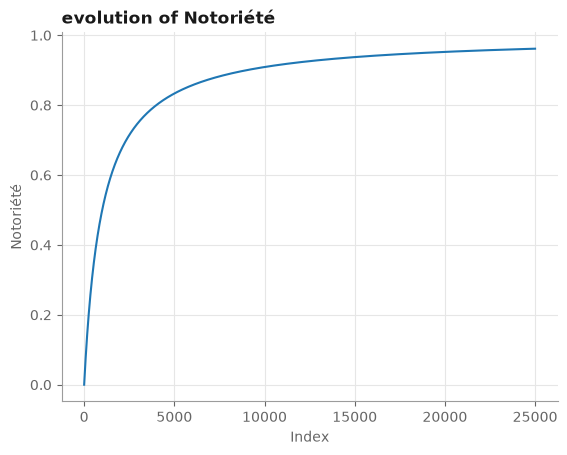

In [241]:
cleanedDataFrame = games.copy().reset_index(drop=True)
voters = cleanedDataFrame[NUMBER_VOTE]

q1, q2, q3 = cleanedDataFrame[NUMBER_VOTE].quantile([0.25, 0.50, 0.75])
print(f"Nombre de votants : Q1 = {q1:.2f} ; médiane = {q2:.2f} ; Q3 = {q3:.2f}  (M = {SIGNIFICATIF_VOTE_NUMBER})")

for v in (100, 1000, 10000, 100000):
    print(f"  {v:>6} votes -> notoriété N = {v / (v + SIGNIFICATIF_VOTE_NUMBER):.2f}")

idx = pd.Index(range(25000))
notorietyTest = pd.DataFrame(
    {NOTORIETY: idx / (idx + SIGNIFICATIF_VOTE_NUMBER)},
    index=idx,
)
evolutionGraph(NOTORIETY, dataFrame=notorietyTest)

- **Appréciation (« apprécié »)** : $A$ = rang centile de la note moyenne $R$, c'est-à-dire la proportion de jeux dont la note est inférieure ou égale à celle du jeu. $A = 0{,}75$ signifie « que ce jeux est mieux note que 75% des jeux ». Utiliser le rang plutôt que la note elle-même place l'appréciation sur la même échelle que la notoriété (de 0 à 1).

$$\text{popularité} = N \times A = \frac{V}{V + M} \times \text{rang centile de } R$$

Le **produit** traduit le « et » de notre définition : un jeu n'est populaire que s'il est à la fois connu **et** apprécié. Si l'un des deux ingrédients est proche de 0, la popularité l'est aussi.

In [242]:
# Durée moyenne = milieu de la fourchette [durée min ; durée max]
cleanedDataFrame[MEAN_TIME] = (cleanedDataFrame[MIN_TIME] + cleanedDataFrame[MAX_TIME]) / 2

# voters = cleanedDataFrame[NUMBER_VOTE]
rating = cleanedDataFrame[AVERAGE_RATING]

# Notoriété N = V / (V + M)  et  appréciation A = rang centile de la note moyenne
cleanedDataFrame[NOTORIETY] = voters / (voters + SIGNIFICATIF_VOTE_NUMBER)
cleanedDataFrame[APPRECIATION] = rating.rank(pct=True)

# Popularité = N x A  (formule retenue)
cleanedDataFrame[POPULARITY] = cleanedDataFrame[NOTORIETY] * cleanedDataFrame[APPRECIATION]

# Les deux autres formules, gardées pour comparaison (sections 4.3 et 6.7)
globalMean = rating.mean()
cleanedDataFrame[POPULARITY_V1] = cleanedDataFrame[NOTORIETY] * rating
cleanedDataFrame[POPULARITY_BAYES] = cleanedDataFrame[NOTORIETY] * rating + (1 - cleanedDataFrame[NOTORIETY]) * globalMean

# Contrôle de la formule : les jeux les plus et les moins populaires
shown = [TITLE, TYPE, NUMBER_VOTE, AVERAGE_RATING, COMPLEXITY, NOTORIETY, APPRECIATION, POPULARITY]
display(cleanedDataFrame.nlargest(10, POPULARITY)[shown].round(4))
display(cleanedDataFrame.nsmallest(10, POPULARITY)[shown])

,Titre,Type,Nombre de votants,Note moyenne,Complexité,Notoriété,Appréciation,Popularité
2,Gloomhaven,Strategy,60276,8.61,3.90,0.9837,0.9930,0.9768
5,Terraforming Mars,Strategy,94074,8.37,3.26,0.9895,0.9843,0.9739
1,Pandemic Legacy: Season 1,Strategy,51950,8.53,2.83,0.9811,0.9902,0.9715
0,Brass: Birmingham,Strategy,41991,8.61,3.89,0.9767,0.9930,0.9699
3,Ark Nova,Strategy,37020,8.53,3.74,0.9737,0.9902,0.9641
10,Spirit Island,Strategy,47542,8.35,4.06,0.9794,0.9832,0.9630
6,Dune: Imperium,Strategy,39629,8.42,3.03,0.9754,0.9864,0.9621
7,Gloomhaven: Jaws of the Lion,Strategy,31558,8.47,3.64,0.9693,0.9882,0.9579
16,Scythe,Strategy,79816,8.16,3.44,0.9876,0.9698,0.9578
12,Twilight Struggle,Strategy,47650,8.25,3.61,0.9794,0.9775,0.9574


,Titre,Type,Nombre de votants,Note moyenne,Complexité,Notoriété,Appréciation,Popularité
12932,Super Deck!,Customizable,79,2.13,1.40,0.073216,0.000077,0.000006
12831,Warmaster Chess 2000,Wargames,52,2.86,2.50,0.049430,0.000231,0.000011
12622,"Civil War Classics, Volume 1: The Battles of P...",Wargames,35,3.30,3.00,0.033816,0.000386,0.000013
12923,Quidditch: The Game,Children's,95,2.85,1.67,0.086758,0.000154,0.000013
12554,Star Patrol,Wargames,33,3.31,2.00,0.031946,0.000463,0.000015
12809,The Civil War: The War That Pitted Brother Aga...,Wargames,53,2.99,3.22,0.050332,0.000309,0.000016
12676,"Operation Elope, 1918-1919",Wargames,35,3.33,2.38,0.033816,0.000579,0.000020
12616,Catch Mag,Children's,31,3.44,1.00,0.030068,0.000771,0.000023
12644,Baby Bird Game,Children's,37,3.50,1.00,0.035680,0.000849,0.000030
12776,Mr. Bucket,Children's,53,3.43,1.00,0.050332,0.000694,0.000035


### 4.2 En clair : pourquoi un rang plutôt que la note brute ?

Notre première idée de base était de multiplier la notoriété par la **note brute** : $N \times R$. Cela semble naturel, mais cela pose un problème : **presque tous les jeux ont une note proche de la moyenne**. Multiplier par la note revient donc à multiplier presque tout le monde par le même nombre (6,65). La note ne change presque rien au classement, qui est dicté par le nombre de votes : la moitié « connu » de notre définition l'emporte, et la moitié « apprécié » disparaît.

C'est comme un examen noté sur deux épreuves, où tout le monde obtient entre 12 et 14 sur 20 à la première, mais entre 0 et 20 à la seconde : la première épreuve ne départage personne, seule la seconde compte.

Notre solution : remplacer la note par son **rang centile** (représente sa position dans le set de donnée sous forme de pourcentage). Les notes, concentrées sur un petit intervalle, sont alors étalées de 0 à 1, comme la notoriété. Un jeu parmi les moins bien notés passe à environ 0,1 et un jeu parmi les mieux notés à environ 0,9 : la note pèse enfin autant que le nombre de votes.

Note moyenne : moyenne = 6.65 ; écart-type = 0.84
Part des jeux dont la note est comprise entre 6 et 7,5 : 63.83%


,10 % inférieurs,10 % supérieurs,Facteur multiplicatif
Note brute R,5.580,7.700,1.380
Rang centile de la note A,0.100,0.901,8.967
Notoriété N,0.045,0.767,17.081


ρ entre la popularité première version (N x R) et le nombre de votants : 0.994
ρ entre la popularité première version (N x R) et la note moyenne : 0.356
ρ entre la popularité formule retenue (N x A) et le nombre de votants : 0.868
ρ entre la popularité formule retenue (N x A) et la note moyenne : 0.671


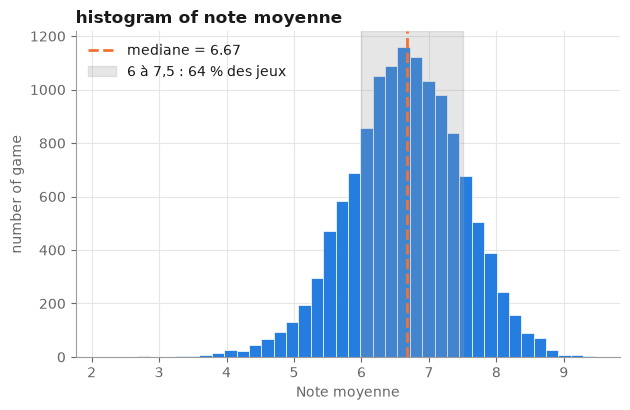

In [243]:
# Les notes sont-elles vraiment concentrées ?
print(f"Note moyenne : moyenne = {rating.mean():.2f} ; écart-type = {rating.std():.2f}")
print(f"Part des jeux dont la note est comprise entre 6 et 7,5 : {rating.between(6, 7.5).mean():.2%}")

# Pour chaque composant de notre formule : valeur d'un jeu « faible » (10 % inférieurs) et d'un jeu « fort » (10 % supérieurs).
# Le facteur multiplicatif indique de combien la popularité peut changer d'un jeu faible à un jeu fort.
composants = {
    "Note brute R": rating,
    "Rang centile de la note A": cleanedDataFrame[APPRECIATION],
    "Notoriété N": cleanedDataFrame[NOTORIETY],
}
rows = {}
for label, serie in composants.items():
    low, high = serie.quantile([0.10, 0.90])
    rows[label] = {f"10 % inférieurs": low, f"10 % supérieurs": high, "Facteur multiplicatif": high / low}
display(pd.DataFrame(rows).T.round(3))

for label, column in {"première version (N x R)": POPULARITY_V1, "formule retenue (N x A)": POPULARITY}.items():
    print(f"ρ entre la popularité {label} et le nombre de votants : {stats.spearmanr(cleanedDataFrame[column], voters).statistic:.3f}")
    print(f"ρ entre la popularité {label} et la note moyenne : {stats.spearmanr(cleanedDataFrame[column], rating).statistic:.3f}")

#! les notes sont-elles concentrées ? de combien chaque composant fait-il varier la popularité ?
pyplot.figure(figsize=(12, 4.2))

pyplot.subplot(1, 2, 1)
histGraph(AVERAGE_RATING)
pyplot.axvspan(6, 7.5, color=COLOR_GREY, alpha=0.25, label=f"6 à 7,5 : {rating.between(6, 7.5).mean() * 100:.0f} % des jeux")
pyplot.legend()

pyplot.tight_layout()
pyplot.show()

**Analyse :**
- **64 % des jeux ont une note entre 6 et 7,5**, pour une moyenne de 6,65 et un écart-type de seulement 0,84.
- Passer d'un jeu « faible » à un jeu « fort » en note brute **multiplie la popularité par environ 1,4 seulement**, alors que le même passage en notoriété la multiplie par environ 17. Avec le rang centile, la note peut la multiplier par environ 9 : elle redevient comparable à la notoriété.
- Conséquence : la popularité de la première version est presque entièrement déterminée par le nombre de votes ($\rho = 0{,}994$) et pas de la note ($\rho = 0{,}356$), alors que celle de la formule retenue dépend à la fois du nombre de votes ($\rho = 0{,}868$) et de la note ($\rho = 0{,}671$).

**En résumé**, nos trois composants se lisent ainsi :
- **Notoriété $N$** : à quel point le jeu est connu (0 = presque personne, 1 = tout le monde), avec un effet qui se stabilise.
- **Appréciation $A$** : où se situe la note du jeu par rapport à celle des autres jeux (0 = parmi les moins bien notés, 1 = parmi les mieux notés).
- **Popularité $= N \times A$** : élevée seulement si le jeu est à la fois **connu et apprécié**.

Cette formule est un **choix de notre part**, justifié par notre définition de la popularité. La section 4.3 la compare honnêtement aux autres formules possibles, et la section 6.7 montre ce que changent les résultats selon la formule.

### 4.3 Pourquoi cette formule plutôt qu'une autre ?

Notre première version était inspirée de la moyenne pondérée bayésienne (utilisée par exemple par IMDb) :

$$\text{popularité}_{v1} = \frac{V}{V + M} \times R$$

La moyenne bayésienne **complète** s'écrit $\frac{V}{V+M}R + \frac{M}{V+M}C$, où $C$ est la note moyenne de tous les jeux : les jeux peu votés sont tirés vers $C$ plutôt que vers 0. Cette formule ne représente pas notre vision d'un classement de popularité. Nous avons donc cherché une autre formule qui tirerait les jeux peu votés vers 0 plutôt que la note moyenne. 

Nous comparons les trois formules sur des critères tirés de **notre définition** (et non sur leur lien avec la complexité) :

1. **« Connu ET apprécié »** : un jeu très connu mais peu apprécié, ou très apprécié mais peu connu, ne doit pas être bien classé. Nous croisons le nombre de votants et la note (« bas » = les 25 % inférieurs, « haut » = les 25 % supérieurs) et regardons le **rang centile moyen** de chaque case (0 = dernier, 1 = premier).
2. **« Suffisamment » connu** : l'effet du nombre de votes doit se stabiliser (voir ci-dessus : c'est le rôle de $N$).
3. **Équilibre** : le nombre de votes **et** la note doivent tous deux compter dans le classement (corrélations de rang $\rho$).

In [244]:
candidates = {"Retenue": POPULARITY, "Première version": POPULARITY_V1, "Bayésienne complète": POPULARITY_BAYES}

# Critère 1 : « connu ET apprécié » -> rang centile moyen dans chacune des quatre cases
vLow, vHigh = voters.quantile([0.25, 0.75])
rLow, rHigh = rating.quantile([0.25, 0.75])
cases = {
    "peu connu, peu apprécié":   (voters <= vLow) & (rating <= rLow),
    "peu connu, très apprécié":  (voters <= vLow) & (rating >= rHigh),
    "très connu, peu apprécié":  (voters >= vHigh) & (rating <= rLow),
    "très connu, très apprécié": (voters >= vHigh) & (rating >= rHigh),
}
rows = {}
for caseName, mask in cases.items():
    rows[caseName] = {"Nombre de jeux": int(mask.sum())}
    for label, column in candidates.items():
        rows[caseName][f"Centile moyen ({label})"] = round(cleanedDataFrame[column].rank(pct=True)[mask].mean(), 2)
display(pd.DataFrame(rows).T)

# Critères 3 et 4 : poids du nombre de votants et de la note
rows = {}
for label, column in candidates.items():
    rows[label] = {
        "ρ avec le nombre de votants": stats.spearmanr(cleanedDataFrame[column], voters).statistic,
        "ρ avec la note moyenne": stats.spearmanr(cleanedDataFrame[column], rating).statistic,
    }
display(pd.DataFrame(rows).T.round(2))

,Nombre de jeux,Centile moyen (Retenue),Centile moyen (Première version),Centile moyen (Bayésienne complète)
"peu connu, peu apprécié",1180.0,0.06,0.09,0.31
"peu connu, très apprécié",739.0,0.35,0.17,0.64
"très connu, peu apprécié",188.0,0.51,0.78,0.02
"très connu, très apprécié",1198.0,0.94,0.92,0.95


,ρ avec le nombre de votants,ρ avec la note moyenne
Retenue,0.87,0.67
Première version,0.99,0.36
Bayésienne complète,0.28,0.90


**Analyse :**
- **Première version** : un jeu très connu mais peu apprécié se classe encore au 78ᵉ centile en moyenne. L'appréciation compte trop peu : la formule suit presque uniquement le nombre de votes ($\rho = 0{,}99$ avec les votes, $0{,}36$ avec la note).
- **Bayésienne complète** : c'est l'inverse. Un jeu très apprécié mais peu connu se classe au 64ᵉ centile, car le nombre de votes ne sert plus qu'à fiabiliser la note ($\rho = 0{,}28$ avec les votes, $0{,}90$ avec la note). Cette formule mesure l'**appréciation**, pas la notoriété : elle ne correspond donc qu'à la moitié de notre définition.
- **Formule retenue** : les deux cases « déséquilibrées » restent à des rangs intermédiaires (35ᵉ et 51ᵉ centiles), la case « connu et apprécié » monte à 94, et les deux composants comptent ($\rho = 0{,}87$ avec les votes et $0{,}67$ avec la note). 

La notoriété garde un poids un peu plus grand que l'appréciation, car le nombre de votes varie sur plusieurs ordres de grandeur (de 30 à 123 256) alors que les notes se concentrent entre 5 et 8. Le choix de la formule influence les résultats : nous comparons donc les trois formules en section 6.7.

## 5. Analyse exploratoire

### 5.1 Vue d'ensemble

In [245]:
cleanedDataFrame.info()
cleanedDataFrame.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 12963 entries, 0 to 12962
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Titre                             12963 non-null  str    
 1   Note moyenne                      12963 non-null  float64
 2   Durée minimum                     12963 non-null  float64
 3   Durée maximum                     12963 non-null  float64
 4   Nombre de votants                 12963 non-null  int64  
 5   Complexité                        12963 non-null  float64
 6   Type                              12963 non-null  str    
 7   Durée moyenne                     12963 non-null  float64
 8   Notoriété                         12963 non-null  float64
 9   Appréciation                      12963 non-null  float64
 10  Popularité                        12963 non-null  float64
 11  Popularité (première version)     12963 non-null  float64
 12  Popularité (bay

,Titre,Note moyenne,Durée minimum,Durée maximum,Nombre de votants,Complexité,Type,Durée moyenne,Notoriété,Appréciation,Popularité,Popularité (première version),Popularité (bayésienne complète)
0,Brass: Birmingham,8.61,60.0,120.0,41991,3.89,Strategy,90.0,0.976739,0.992980,0.969883,8.409726,8.564427
1,Pandemic Legacy: Season 1,8.53,60.0,60.0,51950,2.83,Strategy,60.0,0.981114,0.990164,0.971464,8.368905,8.494509
2,Gloomhaven,8.61,60.0,120.0,60276,3.90,Strategy,90.0,0.983680,0.992980,0.976775,8.469488,8.578026
3,Ark Nova,8.53,90.0,150.0,37020,3.74,Strategy,120.0,0.973698,0.990164,0.964121,8.305644,8.480573
4,Twilight Imperium: Fourth Edition,8.61,240.0,480.0,22123,4.31,Strategy,360.0,0.956753,0.992980,0.950037,8.237643,8.525269
5,Terraforming Mars,8.37,120.0,120.0,94074,3.26,Strategy,120.0,0.989482,0.984263,0.973910,8.281963,8.351917
6,Dune: Imperium,8.42,60.0,120.0,39629,3.03,Strategy,90.0,0.975387,0.986384,0.962106,8.212759,8.376454
7,Gloomhaven: Jaws of the Lion,8.47,30.0,120.0,31558,3.64,Strategy,75.0,0.969286,0.988236,0.957883,8.209849,8.414123
8,War of the Ring: Second Edition,8.53,150.0,180.0,20119,4.21,Thematic,165.0,0.952649,0.990164,0.943279,8.126098,8.441017
9,Star Wars: Rebellion,8.42,180.0,240.0,31079,3.74,Thematic,210.0,0.968827,0.986384,0.955636,8.157523,8.364848


In [246]:
# Résumé statistique des variables quantitatives principales (+ coefficient d'asymétrie)
keyColumns = [COMPLEXITY, AVERAGE_RATING, NUMBER_VOTE, POPULARITY, MEAN_TIME]
summary = cleanedDataFrame[keyColumns].describe().T
summary["asymétrie"] = cleanedDataFrame[keyColumns].skew()
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,asymétrie
Complexité,12963.0,2.24,0.83,1.00,1.56,2.18,2.80,5.00,0.43
Note moyenne,12963.0,6.65,0.84,2.13,6.11,6.67,7.22,9.47,-0.22
Nombre de votants,12963.0,1666.65,5533.70,30.00,94.00,299.00,1055.00,123256.00,9.54
Popularité,12963.0,0.19,0.21,0.00,0.03,0.09,0.28,0.98,1.47
Durée moyenne,12963.0,109.62,689.67,1.00,30.00,52.50,105.00,60000.00,68.78


**Analyse :**
- La **complexité** est centrée vers 2,2 sur 5 et un peu étalée vers la droite : les jeux très complexes sont rares.
- La **note moyenne** est centrée vers 6,7 et très légèrement étalée vers la gauche (quelques jeux très mal notés).
- Le **nombre de votants** est extrêmement asymétrique (asymétrie ≈ 9,5) : la moyenne (≈ 1 667) vaut plus de cinq fois la médiane (299). Quelques jeux très connus concentrent beaucoup de votes.
- La **popularité** (comprise entre 0 et 1) est elle aussi étalée vers la droite (asymétrie ≈ 1,5) : la médiane vaut 0,09 pour une moyenne de 0,19. La plupart des jeux sont peu populaires, quelques-uns le sont énormément.
- La **durée moyenne** est dominée par des valeurs extrêmes (moyenne ≈ 110 min pour une médiane de 52,5 min).

Les variables asymétriques demanderont de la prudence : nous utiliserons des médianes, des échelles logarithmiques pour les graphiques.

### 5.2 Résumé par type de jeu

In [247]:
tableByType = cleanedDataFrame.groupby(TYPE).agg(**{
    "Nombre de jeux": (TITLE, "size"),
    "Complexité (médiane)": (COMPLEXITY, "median"),
    "Note moyenne (moyenne)": (AVERAGE_RATING, "mean"),
    "Votants (médiane)": (NUMBER_VOTE, "median"),
    "Popularité (moyenne)": (POPULARITY, "mean"),
    "Popularité (médiane)": (POPULARITY, "median"),
    "Durée moyenne (médiane)": (MEAN_TIME, "median"),
}).sort_values("Popularité (moyenne)", ascending=False)
display(tableByType.round(3))

,Nombre de jeux,Complexité (médiane),Note moyenne (moyenne),Votants (médiane),Popularité (moyenne),Popularité (médiane),Durée moyenne (médiane)
Type,,,,,,,
Strategy,2334,2.77,7.023,936.0,0.346,0.293,75.0
Thematic,1107,2.40,6.923,669.0,0.276,0.211,70.0
Family,2773,1.66,6.466,738.0,0.225,0.152,30.0
Party,685,1.25,6.323,623.0,0.182,0.116,30.0
Customizable,334,2.43,6.528,264.5,0.181,0.078,45.0
Abstract,1322,1.87,6.290,125.0,0.096,0.032,25.0
Wargames,3463,2.75,6.937,88.0,0.087,0.046,135.0
Children's,945,1.08,5.693,131.0,0.050,0.014,20.0


### 5.3 Distributions des variables

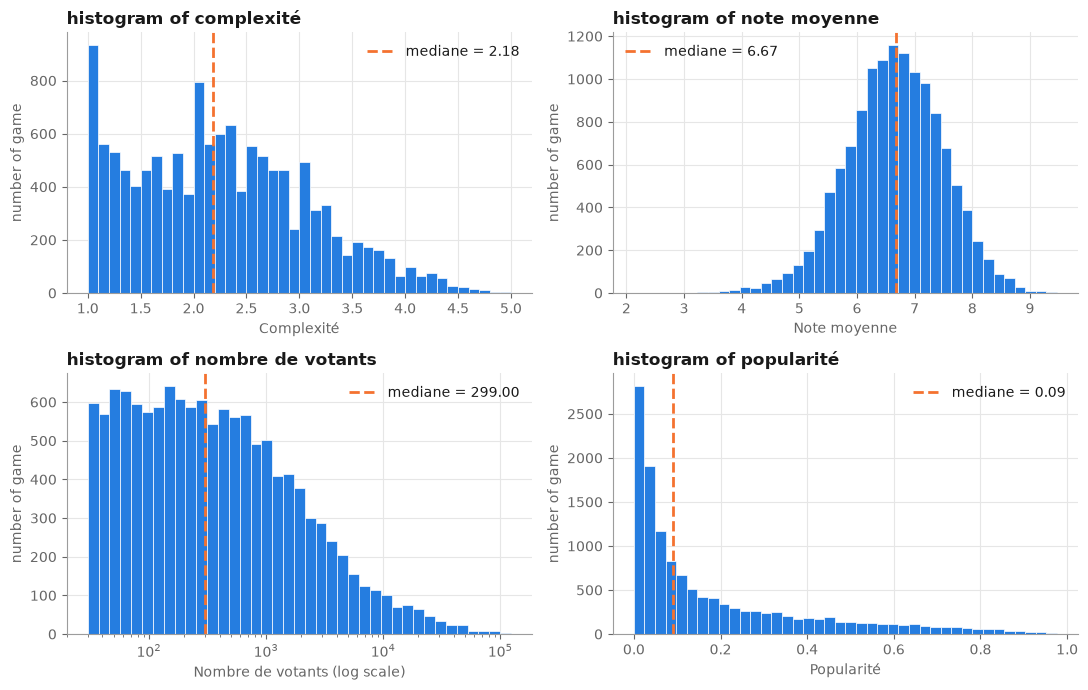

In [248]:
#! distribution des quatre variables principales
pyplot.figure(figsize=(11, 7))

pyplot.subplot(2, 2, 1)
histGraph(COMPLEXITY)
pyplot.subplot(2, 2, 2)
histGraph(AVERAGE_RATING)
pyplot.subplot(2, 2, 3)
histGraph(NUMBER_VOTE, logX=True)
pyplot.subplot(2, 2, 4)
histGraph(POPULARITY)

pyplot.tight_layout()
pyplot.show()

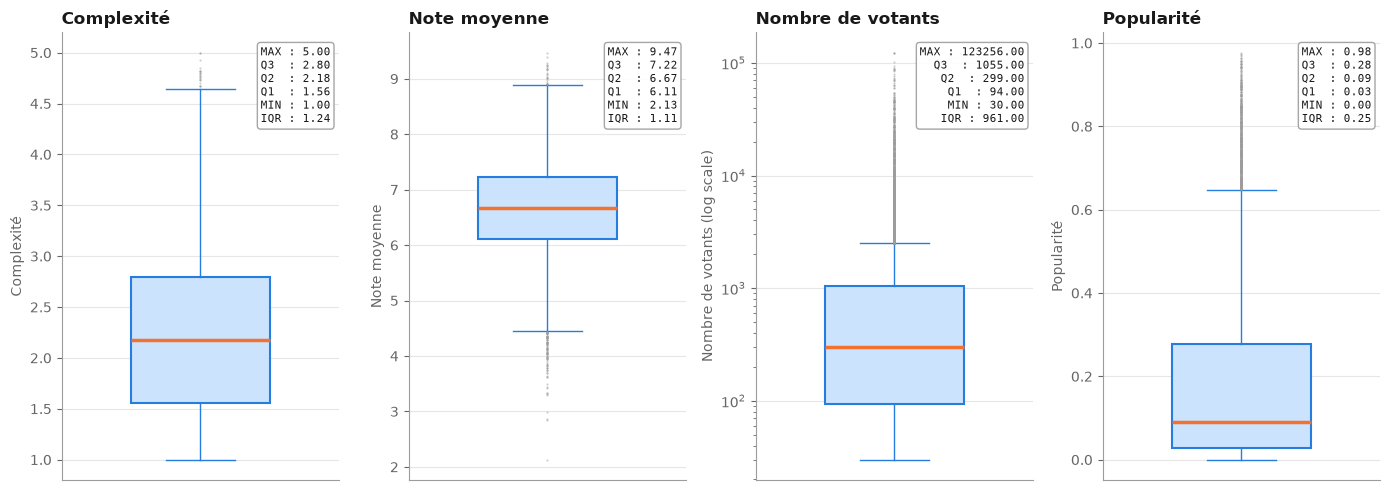

In [249]:
#! boîtes à moustaches (moustaches à 1,5 x IQR ; les points au-delà sont les valeurs « hors boîte »)
pyplot.figure(figsize=(14, 5))

pyplot.subplot(1, 4, 1)
boxplot(COMPLEXITY)
pyplot.subplot(1, 4, 2)
boxplot(AVERAGE_RATING)
pyplot.subplot(1, 4, 3)
boxplot(NUMBER_VOTE, logY=True)
pyplot.subplot(1, 4, 4)
boxplot(POPULARITY)

pyplot.tight_layout()
pyplot.show()

In [250]:
# Nombre de valeurs « hors boîte » : en dessous de Q1 - 1,5 IQR ou au-dessus de Q3 + 1,5 IQR
def outlierSummary(columns, dataFrame=None):
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    rows = {}
    for col in columns:
        q1, q3 = dataFrame[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lowerBound, upperBound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        below = int((dataFrame[col] < lowerBound).sum())
        above = int((dataFrame[col] > upperBound).sum())
        rows[col] = {"Seuil bas": lowerBound, "Seuil haut": upperBound,
                     "Valeurs sous le seuil": below, "Valeurs au-dessus": above,
                     "% de jeux concernés": (below + above) / len(dataFrame) * 100}
    return pd.DataFrame(rows).T

display(outlierSummary([COMPLEXITY, AVERAGE_RATING, NUMBER_VOTE, POPULARITY]).round(2))

,Seuil bas,Seuil haut,Valeurs sous le seuil,Valeurs au-dessus,% de jeux concernés
Complexité,-0.30,4.66,0.0,22.0,0.17
Note moyenne,4.45,8.88,106.0,26.0,1.02
Nombre de votants,-1347.50,2496.50,0.0,1674.0,12.91
Popularité,-0.34,0.65,0.0,741.0,5.72


**Analyse :** Le nombre de votants comporte énormément de valeurs « hors boîte » vers le haut (près de 13 % des jeux) et la popularité en compte aussi (741 jeux, soit 5,7 %). Il ne s'agit pas d'erreurs de saisie mais de **vrais jeux très connus** (Gloomhaven, Terraforming Mars, etc.) : nous les conservons. En revanche, cela rend les moyennes sensibles à quelques jeux et justifie l'usage de méthodes basées sur les rangs en complément.

### 5.4 Les types de jeux

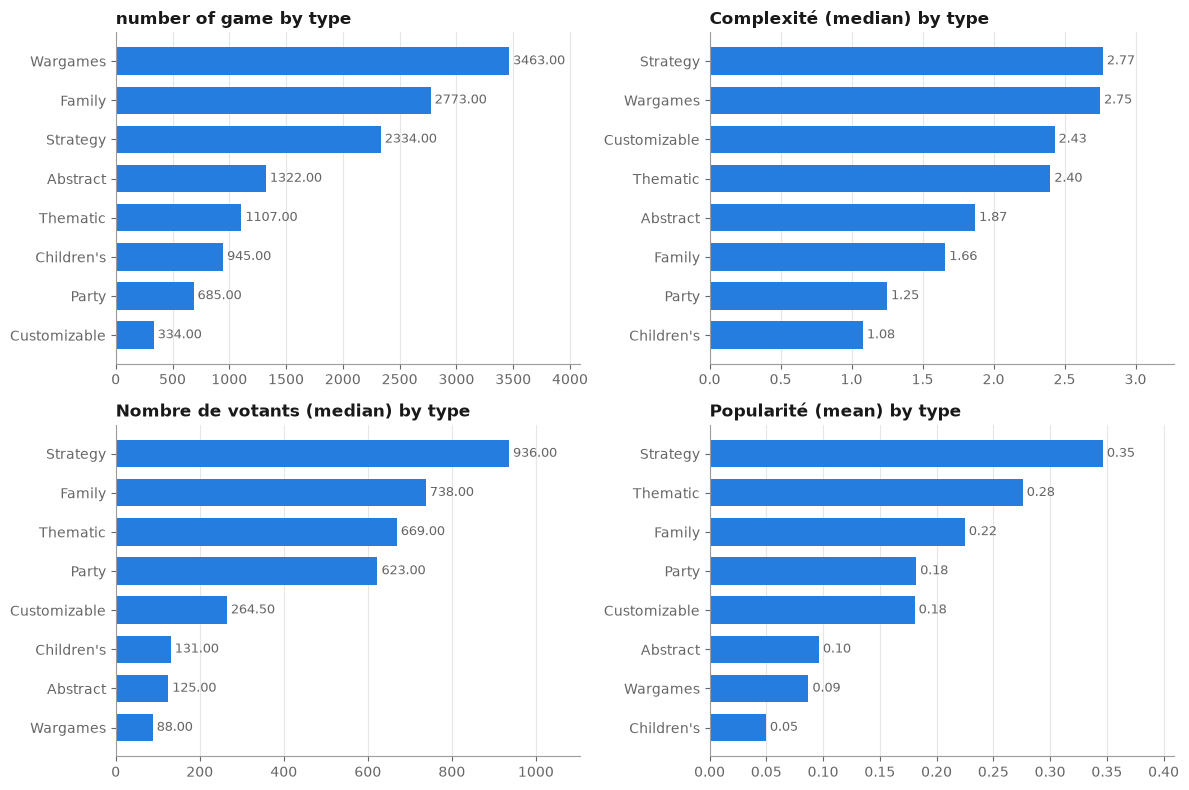

In [251]:
#! effectif, complexité, notoriété et popularité par type
pyplot.figure(figsize=(12, 8))

pyplot.subplot(2, 2, 1)
barGraph(TYPE)
pyplot.subplot(2, 2, 2)
barGraph(TYPE, COMPLEXITY, "median")
pyplot.subplot(2, 2, 3)
barGraph(TYPE, NUMBER_VOTE, "median")
pyplot.subplot(2, 2, 4)
barGraph(TYPE, POPULARITY, "mean")

pyplot.tight_layout()
pyplot.show()

**Analyse :** Le type de jeu pèse lourd. Les **wargames** sont les plus nombreux (3 463 jeux) et font partie des plus complexes (complexité médiane 2,75), mais ils figurent parmi les **moins populaires** (0,09 en moyenne, avant-derniers devant les seuls jeux pour enfants à 0,05) car ils sont peu votés (médiane de 88 votants). À l'inverse, les jeux de **stratégie** ont pratiquement la même complexité médiane (2,77) mais sont les plus populaires (0,35) et nettement plus votés (médiane de 936 votants). Les jeux **Family** et **Party** sont simples mais assez populaires (0,22 et 0,18). Complexité et popularité ne vont donc clairement pas de pair *d'un type à l'autre* : nous y reviendrons en section 6.5.

### 5.5 À quoi ressemblent les jeux les plus populaires ?

Nous isolons le quart des jeux les plus populaires (popularité au-dessus du 3ᵉ quartile).

In [252]:
popularThreshold = cleanedDataFrame[POPULARITY].quantile(0.75)
popularDataFrame = cleanedDataFrame[cleanedDataFrame[POPULARITY] > popularThreshold]
otherDataFrame = cleanedDataFrame[cleanedDataFrame[POPULARITY] <= popularThreshold]
print(f"{len(popularDataFrame)} jeux populaires ({len(popularDataFrame) / len(cleanedDataFrame):.1%} du total), "
      f"seuil de popularité : {popularThreshold:.2f}")

# Part de chaque type parmi tous les jeux, puis parmi les jeux populaires
typeShare = pd.DataFrame({
    "Tous les jeux (%)": cleanedDataFrame[TYPE].value_counts(normalize=True) * 100,
    "25 % les plus populaires (%)": popularDataFrame[TYPE].value_counts(normalize=True) * 100,
})
display(typeShare.sort_values("25 % les plus populaires (%)", ascending=False).round(1))

print(f"\nComplexité médiane : jeux populaires = {popularDataFrame[COMPLEXITY].median():.2f} ; "
      f"autres jeux = {otherDataFrame[COMPLEXITY].median():.2f}")

3241 jeux populaires (25.0% du total), seuil de popularité : 0.28


,Tous les jeux (%),25 % les plus populaires (%)
Type,,
Strategy,18.0,37.7
Family,21.4,28.1
Thematic,8.5,14.0
Wargames,26.7,7.0
Party,5.3,5.0
Abstract,10.2,4.4
Customizable,2.6,2.7
Children's,7.3,1.2



Complexité médiane : jeux populaires = 2.38 ; autres jeux = 2.10


**Analyse :** Les jeux populaires sont surtout des jeux de **stratégie, Family et Thematic** (80 % des jeux populaires), alors que les wargames y sont très sous-représentés (7 % des jeux populaires contre 27 % de l'ensemble). Leur complexité médiane est un peu plus élevée que celle des autres jeux (2,38 contre 2,10) : ce que les jeux populaires ont en commun, c'est d'abord leur **type**, et dans une moindre mesure leur complexité. La suite vérifiera cela rigoureusement.

## 6. Application des outils statistiques

### 6.1 Un premier regard : complexité, note et nombre de votants

Regardons comment la complexité se relie à chacune de ces trois grandeurs. Sur chaque graphique, plus la teinte est foncée, plus il y a de jeux ; la ligne orange donne la moyenne par classe de complexité.

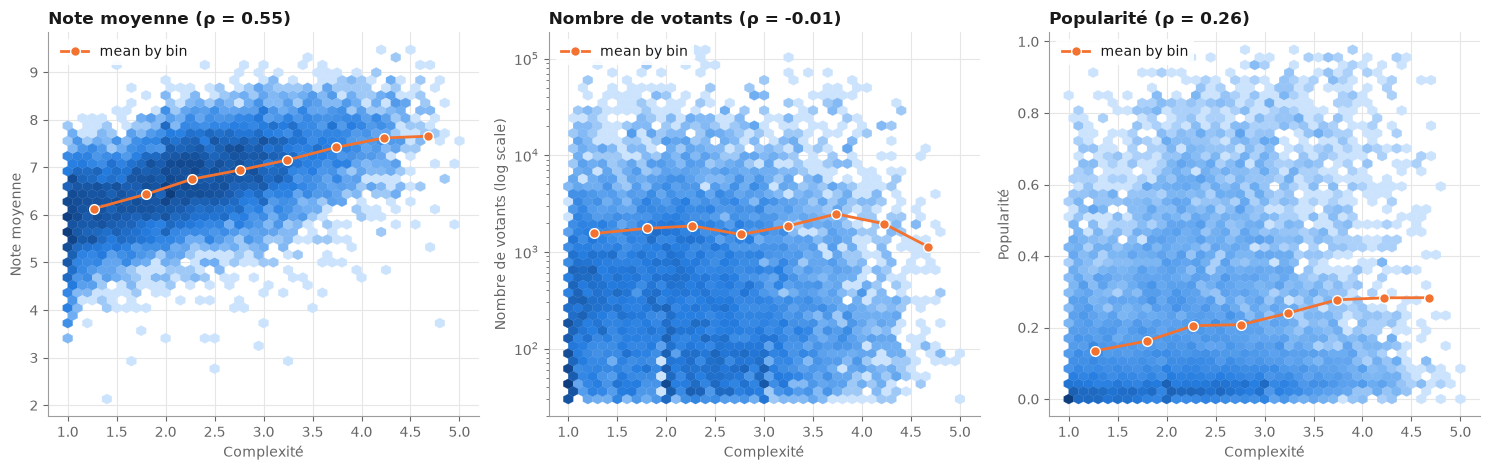

In [253]:
#! la complexité face à la note, au nombre de votants et à la popularité
classEdges = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]

rhoRating = stats.spearmanr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[AVERAGE_RATING]).statistic
rhoVoters = stats.spearmanr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[NUMBER_VOTE]).statistic
rhoPopularity = stats.spearmanr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[POPULARITY]).statistic

pyplot.figure(figsize=(15, 4.8))
pyplot.subplot(1, 3, 1)
scatterGraph(COMPLEXITY, AVERAGE_RATING, classEdges=classEdges,
             graphTitle=f"Note moyenne (ρ = {rhoRating:.2f})")
pyplot.subplot(1, 3, 2)
scatterGraph(COMPLEXITY, NUMBER_VOTE, logY=True, classEdges=classEdges,
             graphTitle=f"Nombre de votants (ρ = {rhoVoters:.2f})")
pyplot.subplot(1, 3, 3)
scatterGraph(COMPLEXITY, POPULARITY, classEdges=classEdges,
             graphTitle=f"Popularité (ρ = {rhoPopularity:.2f})")
pyplot.tight_layout()
pyplot.show()

**Analyse :** Les jeux plus complexes sont **nettement mieux notés** (la ligne monte clairement), mais **pas davantage votés** (la ligne reste à peu près au même niveau). Notre popularité combine ces deux composants : on peut donc s'attendre à une corrélation positive avec la complexité, mais nettement moins forte qu'avec la note seule.

### 6.2 Mesurer la corrélation

Nous calculons deux coefficients : le $r$ de **Pearson** (relation linéaire) et le $\rho$ de **Spearman** (relation monotone, calculée sur les rangs, donc insensible aux valeurs extrêmes). Les p-valeurs correspondent aux tests de $H_0$ : « pas de corrélation ».

In [254]:
def formatP(p):
    # les très petites p-valeurs sont écrites « < 1e-300 » plutôt que 0.0
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

rows = []
for col in [POPULARITY, AVERAGE_RATING, NUMBER_VOTE]:
    pearson = stats.pearsonr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[col])
    spearman = stats.spearmanr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[col])
    rows.append({
        f"Variable comparée à « {COMPLEXITY} »": col,
        "r (Pearson)": round(pearson.statistic, 3), "p-valeur (Pearson)": formatP(pearson.pvalue),
        "ρ (Spearman)": round(spearman.statistic, 3), "p-valeur (Spearman)": formatP(spearman.pvalue),
    })
display(pd.DataFrame(rows).set_index(f"Variable comparée à « {COMPLEXITY} »"))

,r (Pearson),p-valeur (Pearson),ρ (Spearman),p-valeur (Spearman)
Variable comparée à « Complexité »,,,,
Popularité,0.220,2.0e-142,0.256,7.6e-193
Note moyenne,0.543,< 1e-300,0.548,< 1e-300
Nombre de votants,0.037,3.1e-05,-0.010,2.4e-01


,Nombre de jeux,Popularité (moyenne),Popularité (médiane),Votants (médiane),Note moyenne (moyenne)
Classe de complexité,,,,,
"[1 ; 1,5]",2470,0.135,0.065,412.5,6.131
"]1,5 ; 2]",2529,0.162,0.078,346.0,6.434
"]2 ; 2,5]",2713,0.205,0.110,347.0,6.752
"]2,5 ; 3]",2329,0.208,0.104,249.0,6.944
"]3 ; 3,5]",1276,0.240,0.138,251.5,7.153
"]3,5 ; 4]",702,0.277,0.166,277.5,7.418
"]4 ; 4,5]",282,0.283,0.163,236.5,7.616
"]4,5 ; 5]",51,0.283,0.163,298.0,7.654


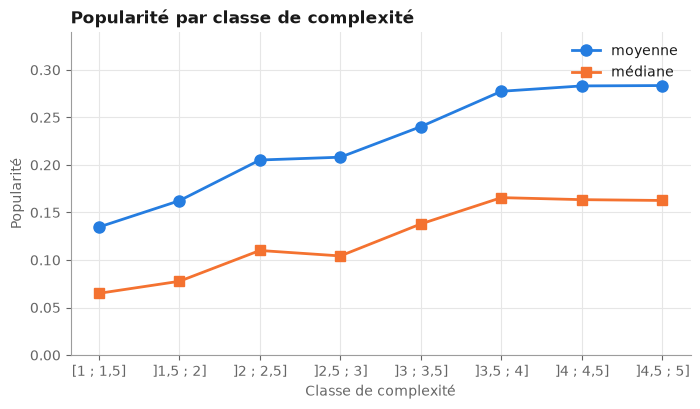

In [255]:
# Popularité moyenne et médiane par classe de complexité
cleanedDataFrame["Classe de complexité"] = pd.cut(
    cleanedDataFrame[COMPLEXITY], classEdges,
    labels=["[1 ; 1,5]", "]1,5 ; 2]", "]2 ; 2,5]", "]2,5 ; 3]", "]3 ; 3,5]", "]3,5 ; 4]", "]4 ; 4,5]", "]4,5 ; 5]"])

byClass = cleanedDataFrame.groupby("Classe de complexité", observed=True).agg(**{
    "Nombre de jeux": (TITLE, "size"),
    "Popularité (moyenne)": (POPULARITY, "mean"),
    "Popularité (médiane)": (POPULARITY, "median"),
    "Votants (médiane)": (NUMBER_VOTE, "median"),
    "Note moyenne (moyenne)": (AVERAGE_RATING, "mean"),
})
display(byClass.round(3))

# Représentation graphique : moyenne et médiane de la popularité par classe
pyplot.figure(figsize=(8, 4.2))
pyplot.plot(byClass.index.astype(str), byClass["Popularité (moyenne)"], color=COLOR_MAIN, marker="o",
            markersize=8, linewidth=2, label="moyenne")
pyplot.plot(byClass.index.astype(str), byClass["Popularité (médiane)"], color=COLOR_ACCENT, marker="s",
            markersize=7, linewidth=2, label="médiane")
pyplot.ylim(0, byClass["Popularité (moyenne)"].max() * 1.2)
pyplot.title("Popularité par classe de complexité")
pyplot.xlabel("Classe de complexité")
pyplot.ylabel(POPULARITY)
pyplot.legend()
pyplot.show()

**Analyse :** La corrélation entre complexité et popularité est **positive mais faible** ($r \approx 0{,}22$ ; $\rho \approx 0{,}26$). La complexité est en revanche nettement corrélée à la note ($\rho \approx 0{,}55$) et pas au nombre de votants ($\rho \approx -0{,}01$) : le lien avec la popularité vient donc de la composante « appréciation ». Dans le tableau par classe, la popularité moyenne augmente régulièrement avec la complexité, de 0,11 pour les jeux les plus simples à 0,28 pour les plus complexes (environ 2,4 fois plus). La médiane suit la même tendance (de 0,05 à 0,16), avec un seul léger recul. Nous allons tester si cette corrélation peut être due au hasard.

### 6.3 Test d'hypothèse principal : la pente de la droite de régression

Nous modélisons la popularité par la complexité avec la **régression linéaire simple**

$$\text{Popularité}_i = \beta_0 + \beta_1 \times \text{Complexité}_i + \varepsilon_i$$

Si la complexité n'a aucun lien linéaire avec la popularité, la pente $\beta_1$ vaut 0. Tester $\beta_1 = 0$ revient exactement à tester l'absence de corrélation linéaire ($\rho = 0$).

**1. Seuil de significativité.** $\alpha = 5\,\%$, le seuil usuel : il fixe à 5 % le risque de conclure à tort à une relation qui n'existe pas. Le risque d'une mauvaise décision est ici modéré (il ne s'agit pas d'un enjeu vital), un seuil plus sévère n'est donc pas nécessaire. Avec 12 963 jeux, le test est très puissant : nous vérifierons que la décision ne change pas avec $\alpha = 1\,\%$ ou $0{,}1\,\%$.

**2. Hypothèses.**
- $H_0 : \beta_1 = 0$ (la complexité n'a pas d'effet linéaire sur la popularité) ;
- $H_1 : \beta_1 \neq 0$.

Le test est **bilatéral** : notre question de départ demande si les jeux complexes sont « plus *ou* moins » populaires, sans direction postulée. Un test unilatéral n'aurait de sens que si une théorie nous imposait un sens avant d'observer les données. Choisir le sens après avoir vu que la pente est positive augmenterait artificiellement le risque d'erreur.

**3. Test et statistique.** Test de Student sur le coefficient : sous $H_0$,
$$T = \frac{\hat\beta_1}{SE(\hat\beta_1)} \sim t_{n-2}, \qquad SE(\hat\beta_1) = \sqrt{\frac{SSE/(n-2)}{\sum_i (x_i-\bar x)^2}}$$
Conditions : relation linéaire, observations indépendantes, variance des résidus constante, résidus approximativement normaux (vérifiées en 6.4 ; avec $n$ très grand, la normalité est peu critique).

In [256]:
# Calcul « à la main » de la régression et du test (x = complexité, y = popularité)
x = cleanedDataFrame[COMPLEXITY].to_numpy()
y = cleanedDataFrame[POPULARITY].to_numpy()
n = len(x)

Sxx = ((x - x.mean()) ** 2).sum()
Sxy = ((x - x.mean()) * (y - y.mean())).sum()
B1 = Sxy / Sxx                      # pente
B0 = y.mean() - B1 * x.mean()       # ordonnée à l'origine

residuals = y - (B0 + B1 * x)
SSE = (residuals ** 2).sum()
degrees = n - 2                     # degrés de liberté
SE_B1 = np.sqrt(SSE / degrees / Sxx)

T_obs = B1 / SE_B1                                   # statistique observée
T_crit = stats.t.ppf(1 - ALPHA / 2, degrees)         # valeur critique (test bilatéral)
p_value = 2 * stats.t.sf(abs(T_obs), degrees)        # p-valeur bilatérale
confInterval = (B1 - T_crit * SE_B1, B1 + T_crit * SE_B1)
R2 = 1 - SSE / ((y - y.mean()) ** 2).sum()

print(f"n = {n}, degrés de liberté = {degrees}")
print(f"B0 = {B0:.4f}    B1 = {B1:.4f}    SE(B1) = {SE_B1:.4f}")
print(f"T observé = {T_obs:.2f}")
print(f"Région de rejet (α = {ALPHA:.0%}, bilatéral) : |T| > {T_crit:.3f}")
print(f"p-valeur = {p_value:.2e}")
print(f"IC à 95 % de B1 : [{confInterval[0]:.4f} ; {confInterval[1]:.4f}]")
print(f"R² = {R2:.4f}   (r = {np.sqrt(R2):.3f})")

# Vérification avec la fonction toute faite de scipy
check = stats.linregress(x, y)
assert np.isclose(check.slope, B1) and np.isclose(check.intercept, B0) and np.isclose(check.pvalue, p_value)
print("Vérification linregress : identique ✔")

# La décision change-t-elle avec un seuil plus sévère ?
for alpha in (0.05, 0.01, 0.001):
    print(f"α = {alpha:<5} -> {'on rejette H0' if p_value < alpha else 'on ne rejette pas H0'}")

n = 12963, degrés de liberté = 12961
B0 = 0.0572    B1 = 0.0570    SE(B1) = 0.0022
T observé = 25.73
Région de rejet (α = 5%, bilatéral) : |T| > 1.960
p-valeur = 2.05e-142
IC à 95 % de B1 : [0.0526 ; 0.0613]
R² = 0.0486   (r = 0.220)
Vérification linregress : identique ✔
α = 0.05  -> on rejette H0
α = 0.01  -> on rejette H0
α = 0.001 -> on rejette H0


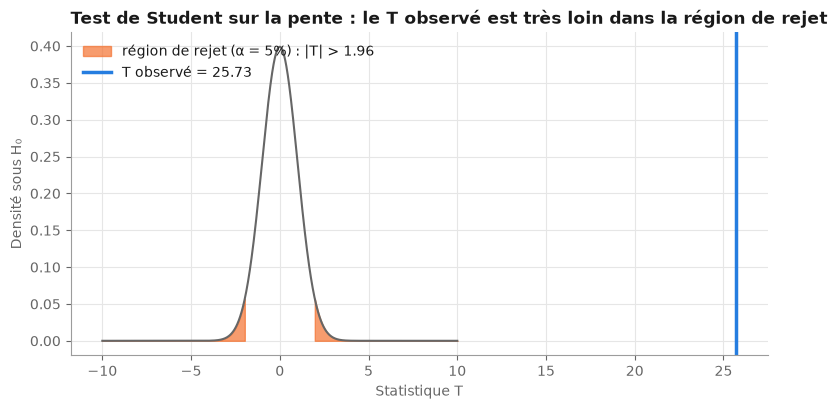

In [257]:
#! région de rejet et statistique observée
tValues = np.linspace(-10, 10, 1000)
density = stats.t.pdf(tValues, degrees)

pyplot.figure(figsize=(9, 4.2))
pyplot.plot(tValues, density, color=COLOR_TEXT_2, linewidth=1.5)
pyplot.fill_between(tValues, density, where=(tValues <= -T_crit), color=COLOR_ACCENT, alpha=0.7,
                    label=f"région de rejet (α = {ALPHA:.0%}) : |T| > {T_crit:.2f}")
pyplot.fill_between(tValues, density, where=(tValues >= T_crit), color=COLOR_ACCENT, alpha=0.7)
pyplot.axvline(T_obs, color=COLOR_MAIN, linewidth=2.5, label=f"T observé = {T_obs:.2f}")
pyplot.title("Test de Student sur la pente : le T observé est très loin dans la région de rejet")
pyplot.xlabel("Statistique T")
pyplot.ylabel("Densité sous H₀")
pyplot.legend(loc="upper left")
pyplot.show()

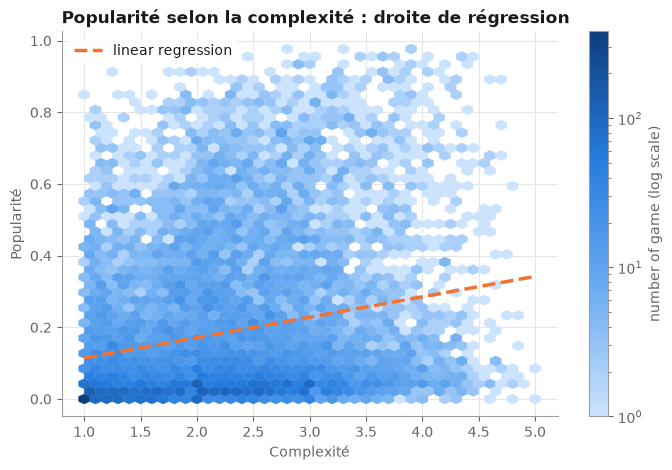

In [258]:
#! la droite de régression sur les données
pyplot.figure(figsize=(8, 5))
scatterGraph(COMPLEXITY, POPULARITY, lineParams=(B0, B1), showColorbar=True,
             graphTitle="Popularité selon la complexité : droite de régression")
pyplot.show()

**4. Conclusion du test.** $T_{obs} \approx 25{,}7$ est très supérieur à la valeur critique $1{,}96$ : il se situe dans la région de rejet. La p-valeur ($\approx 2 \times 10^{-142}$) est très inférieure à $\alpha$, et même à $0{,}1\,\%$. **On rejette $H_0$** : il existe une relation linéaire positive statistiquement significative entre la complexité et la popularité.

**Quelle est l'importance de l'effet ?** La pente vaut $\hat\beta_1 \approx 0{,}057$ (IC à 95 % : $[0{,}053 ; 0{,}061]$) : un point de complexité en plus s'accompagne en moyenne de 0,057 point de popularité en plus, sur une échelle de 0 à 1 où l'écart-type est d'environ 0,21 (soit environ un quart d'écart-type par point de complexité). Le coefficient de détermination vaut $R^2 \approx 0{,}049$ : **la complexité explique environ 5 % des différences de popularité**. C'est un effet **réel mais faible** : avec 12 963 jeux, le test détecte même une relation minuscule, et c'est la taille de l'effet ($r \approx 0{,}22$, $R^2 \approx 5\,\%$) qui dit qu'il ne faut pas la surestimer.

### 6.4 Vérification des conditions du modèle

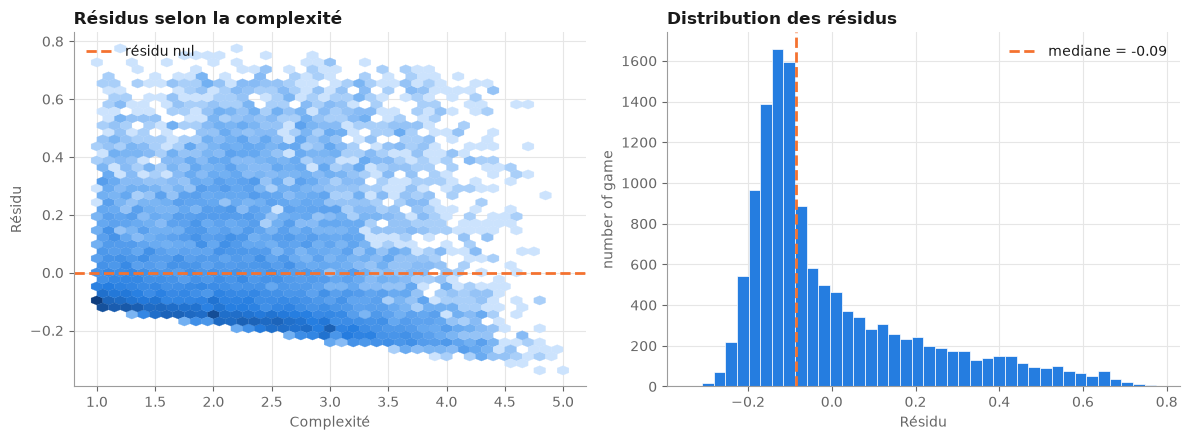

Asymétrie des résidus : 1.36
Corrélation entre la complexité et |résidu| (Spearman) : 0.36 (p = < 1e-300)

Écart-type des résidus par classe de complexité :
Classe de complexité
[1 ; 1,5]    0.17
]1,5 ; 2]    0.19
]2 ; 2,5]    0.22
]2,5 ; 3]    0.23
]3 ; 3,5]    0.25
]3,5 ; 4]    0.27
]4 ; 4,5]    0.28
]4,5 ; 5]    0.27


In [259]:
#! analyse des résidus de la régression
cleanedDataFrame["Résidu"] = residuals

pyplot.figure(figsize=(12, 4.5))
pyplot.subplot(1, 2, 1)
scatterGraph(COMPLEXITY, "Résidu", graphTitle="Résidus selon la complexité")
pyplot.axhline(0, color=COLOR_ACCENT, linestyle="--", linewidth=2, label="résidu nul")
pyplot.legend(loc="upper left")
pyplot.subplot(1, 2, 2)
histGraph("Résidu", graphTitle="Distribution des résidus")
pyplot.tight_layout()
pyplot.show()

print(f"Asymétrie des résidus : {stats.skew(residuals):.2f}")
rhoSpread = stats.spearmanr(cleanedDataFrame[COMPLEXITY], np.abs(residuals))
print(f"Corrélation entre la complexité et |résidu| (Spearman) : {rhoSpread.statistic:.2f} (p = {formatP(rhoSpread.pvalue)})")
print("\nÉcart-type des résidus par classe de complexité :")
print(cleanedDataFrame.groupby("Classe de complexité", observed=True)["Résidu"].std().round(2).to_string())

**Analyse :** Deux conditions ne sont pas parfaitement respectées : les résidus sont **asymétriques** (asymétrie ≈ 1,4, ils ont une longue queue vers le haut) et leur **dispersion augmente avec la complexité** (l'écart-type des résidus passe de 0,16 pour les jeux les plus simples à 0,27 pour les plus complexes : les jeux complexes sont plus hétérogènes en popularité). Avec $n = 12\,963$, l'asymétrie pèse peu (théorème central limite), mais l'hétérogénéité de variance peut rendre la p-valeur un peu optimiste. Pour ne pas dépendre de ces conditions, nous confirmons avec un test **non paramétrique** : le $\rho$ de Spearman, calculé en 6.2, donne $\rho \approx 0{,}26$ avec une p-valeur ≈ $10^{-192}$. La conclusion est la même : **corrélation positive, significative, mais faible**.

### 6.5 Le rôle du type de jeu

En 5.4, nous avons vu que les wargames sont complexes mais impopulaires, alors que les jeux Family sont simples mais populaires. Le type de jeu pourrait donc **brouiller** le lien entre complexité et popularité. Regardons la corrélation *à l'intérieur de chaque type*.

In [260]:
# Corrélation complexité ~ popularité à l'intérieur de chaque type (IC 95 % par transformation de Fisher)
rows = []
for typeName, group in cleanedDataFrame.groupby(TYPE):
    res = stats.pearsonr(group[COMPLEXITY], group[POPULARITY])
    low, high = res.confidence_interval()
    rows.append({TYPE: typeName, "nombre": len(group), "r (Pearson)": res.statistic, "IC95 bas": low, "IC95 haut": high, "p-valeur": res.pvalue})
res = stats.pearsonr(cleanedDataFrame[COMPLEXITY], cleanedDataFrame[POPULARITY])
low, high = res.confidence_interval()
rows.append({TYPE: "Tous types confondus", "nombre": len(cleanedDataFrame), "r (Pearson)": res.statistic, "IC95 bas": low, "IC95 haut": high, "p-valeur": res.pvalue})

tableR = pd.DataFrame(rows).set_index(TYPE)
shownR = tableR.copy()
shownR["p-valeur"] = shownR["p-valeur"].map(formatP)
display(shownR.round(3))

,nombre,r (Pearson),IC95 bas,IC95 haut,p-valeur
Type,,,,,
Abstract,1322,0.169,0.116,0.221,6.0e-10
Children's,945,0.138,0.075,0.200,2.0e-05
Customizable,334,0.454,0.365,0.535,2.1e-18
Family,2773,0.279,0.245,0.313,6.9e-51
Party,685,0.080,0.005,0.154,3.6e-02
Strategy,2334,0.273,0.235,0.310,3.6e-41
Thematic,1107,0.348,0.295,0.399,7.9e-33
Wargames,3463,0.245,0.214,0.276,1.4e-48
Tous types confondus,12963,0.220,0.204,0.237,2.0e-142


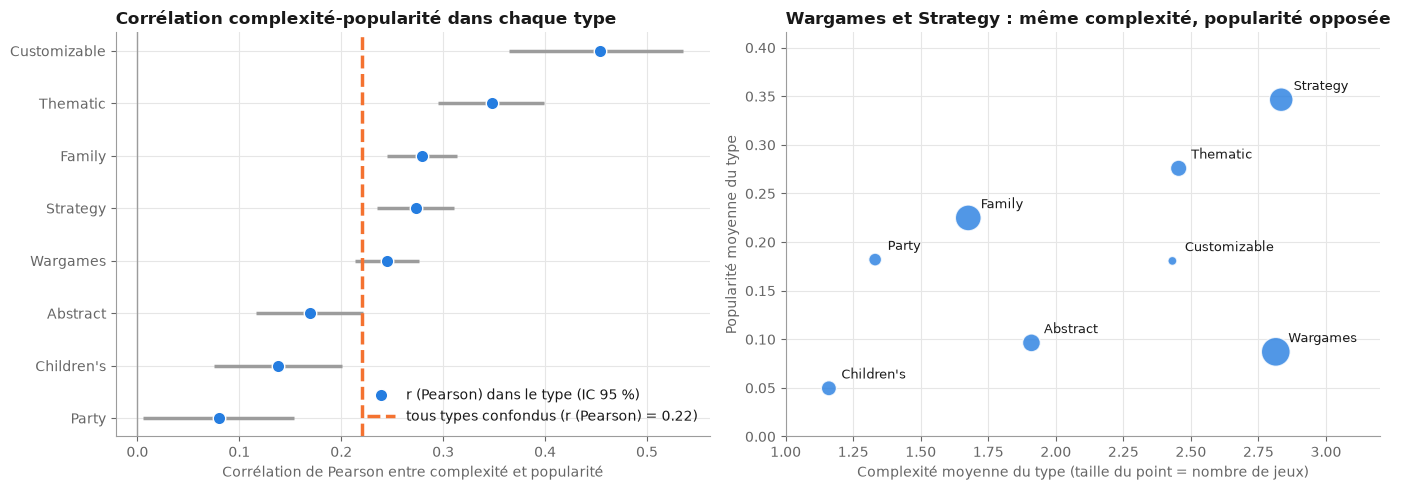

In [261]:
#! à gauche : corrélation dans chaque type ; à droite : moyennes par type
figure, axes = pyplot.subplots(1, 2, figsize=(14, 5))

# --- à gauche : r et son intervalle de confiance, type par type
byType = tableR.drop(index="Tous types confondus").sort_values("r (Pearson)")
positions = np.arange(len(byType))
axes[0].hlines(positions, byType["IC95 bas"], byType["IC95 haut"], color=COLOR_GREY, linewidth=2.5)
axes[0].plot(byType["r (Pearson)"], positions, "o", color=COLOR_MAIN, markersize=9, markeredgecolor="white", label="r (Pearson) dans le type (IC 95 %)")
axes[0].axvline(0, color=COLOR_GREY, linewidth=1)
overallR = tableR.loc["Tous types confondus", "r (Pearson)"]
axes[0].axvline(overallR, color=COLOR_ACCENT, linestyle="--", linewidth=2.5, label=f"tous types confondus (r (Pearson) = {overallR:.2f})")
axes[0].set_yticks(positions)
axes[0].set_yticklabels(byType.index)
axes[0].set_xlabel("Corrélation de Pearson entre complexité et popularité")
axes[0].set_title("Corrélation complexité-popularité dans chaque type")
axes[0].legend(loc="lower right")

# --- à droite : un point par type (taille = nombre de jeux)
typeMeans = cleanedDataFrame.groupby(TYPE).agg(c=(COMPLEXITY, "mean"), p=(POPULARITY, "mean"), n=(TITLE, "size"))
axes[1].scatter(typeMeans["c"], typeMeans["p"], s=typeMeans["n"] / 8, color=COLOR_MAIN, alpha=0.8, edgecolor="white")
for typeName, row in typeMeans.iterrows():
    axes[1].annotate(typeName, (row["c"], row["p"]), textcoords="offset points", xytext=(9, 7), fontsize=9)
axes[1].set_xlim(1, 3.2)
axes[1].set_ylim(0, typeMeans["p"].max() * 1.2)
axes[1].set_xlabel("Complexité moyenne du type (taille du point = nombre de jeux)")
axes[1].set_ylabel("Popularité moyenne du type")
axes[1].set_title("Wargames et Strategy : même complexité, popularité opposée")

pyplot.tight_layout()
pyplot.show()

In [262]:
# Le type explique-t-il la popularité et la complexité ? (ANOVA à un facteur, taille d'effet η²)
def etaSquared(column, dataFrame=None):
    # part de la variance de `column` expliquée par le type = SC inter-groupes / SC totale
    dataFrame = cleanedDataFrame if dataFrame is None else dataFrame
    grandMean = dataFrame[column].mean()
    ssBetween = dataFrame.groupby(TYPE)[column].agg(lambda s: len(s) * (s.mean() - grandMean) ** 2).sum()
    ssTotal = ((dataFrame[column] - grandMean) ** 2).sum()
    return ssBetween / ssTotal

groupsPopularity = [g[POPULARITY].to_numpy() for _, g in cleanedDataFrame.groupby(TYPE)]
anova = stats.f_oneway(*groupsPopularity)
kruskal = stats.kruskal(*groupsPopularity)
print(f"ANOVA (popularité selon le type) : F = {anova.statistic:.0f}, p = {formatP(anova.pvalue)}")
print(f"Kruskal-Wallis (version basée sur les rangs) : H = {kruskal.statistic:.0f}, p = {formatP(kruskal.pvalue)}")
print(f"\nPart de variance expliquée par le type :")
print(f"  - de la popularité : η² = {etaSquared(POPULARITY):.1%}")
print(f"  - de la complexité : η² = {etaSquared(COMPLEXITY):.1%}")
print(f"Rappel : la complexité explique {R2:.1%} de la variance de la popularité (R²).")

ANOVA (popularité selon le type) : F = 543, p = < 1e-300
Kruskal-Wallis (version basée sur les rangs) : H = 3590, p = < 1e-300

Part de variance expliquée par le type :
  - de la popularité : η² = 22.7%
  - de la complexité : η² = 52.9%
Rappel : la complexité explique 4.9% de la variance de la popularité (R²).


**Analyse :**
- À l'intérieur de chaque type, la corrélation reste **positive et significative** ($r$ entre 0,08 et 0,45 ; Party : $p = 0{,}036$, de justesse). Elle est du même ordre que sur l'ensemble ($r = 0{,}22$) : plus forte pour Customizable (0,45) et Thematic (0,35), plus faible pour Party, Children's et Abstract. Le type ne fait donc pas disparaître le lien entre complexité et popularité, il le module légèrement.
- Le **type explique ≈ 23 % de la variance de la popularité**, soit près de 5 fois plus que la complexité (≈ 5 %). Et il explique plus de la moitié de la variance de la complexité (≈ 53 %) : la complexité est en grande partie un « reflet » du type.
- Entre types, le tableau est contrasté : les wargames et les jeux de stratégie ont la même complexité moyenne mais des popularités opposées (graphique de droite).

### 6.6 Test complémentaire : comparer les jeux « simples » et « complexes »

Notre question de départ compare des **moyennes** : « les jeux complexes sont-ils, *en moyenne*, plus populaires que les jeux simples ? ». Nous formons deux groupes avec la **médiane de la complexité** comme frontière (seuil non arbitraire, groupes de tailles égales) : jeux « simples » (complexité ≤ médiane) et jeux « complexes » (> médiane).

1. **Seuil** : $\alpha = 5\,\%$.
2. **Hypothèses** : $H_0 : \mu_{complexes} = \mu_{simples}$ contre $H_1 : \mu_{complexes} \neq \mu_{simples}$ (bilatéral, pour la même raison qu'en 6.3).
3. **Test** : test de Student pour deux échantillons indépendants, **version de Welch** (sans supposer des variances égales, ce que les écarts-types observés ne permettent pas). Statistique $T = \dfrac{\bar x_{c} - \bar x_{s}}{\sqrt{s_c^2/n_c + s_s^2/n_s}}$, loi de Student sous $H_0$. Pour ne pas dépendre de la normalité (la popularité est asymétrique), nous ajoutons le test non paramétrique de **Mann-Whitney**.

Frontière : complexité médiane = 2.18
Jeux simples   : n = 6483, popularité moyenne = 0.148, médiane = 0.067, écart-type = 0.183
Jeux complexes : n = 6480, popularité moyenne = 0.222, médiane = 0.117, écart-type = 0.237

Test de Welch : T = 19.83 ; ddl = 12171 ; région de rejet |T| > 1.96 ; p = 3.4e-86
Différence de moyennes (complexes - simples) = 0.074, IC à 95 % : [0.066 ; 0.081]
Taille d'effet (d de Cohen) = 0.35

Mann-Whitney : p = 7.9e-107


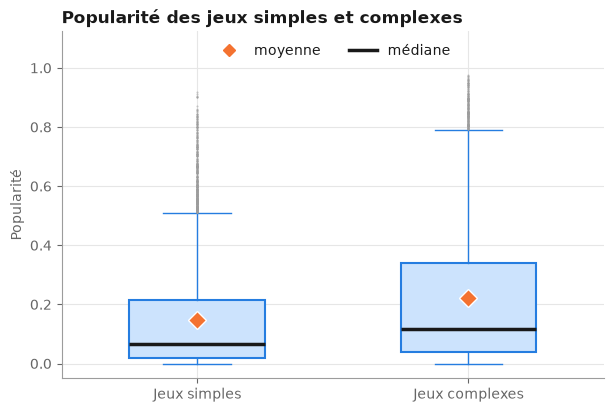

In [263]:
medianComplexity = cleanedDataFrame[COMPLEXITY].median()
simple = cleanedDataFrame.loc[cleanedDataFrame[COMPLEXITY] <= medianComplexity, POPULARITY]
complexe = cleanedDataFrame.loc[cleanedDataFrame[COMPLEXITY] > medianComplexity, POPULARITY]

welch = stats.ttest_ind(complexe, simple, equal_var=False)
tCritWelch = stats.t.ppf(1 - ALPHA / 2, welch.df)
difference = complexe.mean() - simple.mean()
diffLow, diffHigh = welch.confidence_interval()
pooledSd = np.sqrt(((len(simple) - 1) * simple.var() + (len(complexe) - 1) * complexe.var()) / (len(simple) + len(complexe) - 2))
mannWhitney = stats.mannwhitneyu(complexe, simple, alternative="two-sided")

print(f"Frontière : complexité médiane = {medianComplexity:.2f}")
print(f"Jeux simples   : n = {len(simple)}, popularité moyenne = {simple.mean():.3f}, médiane = {simple.median():.3f}, écart-type = {simple.std():.3f}")
print(f"Jeux complexes : n = {len(complexe)}, popularité moyenne = {complexe.mean():.3f}, médiane = {complexe.median():.3f}, écart-type = {complexe.std():.3f}")
print(f"\nTest de Welch : T = {welch.statistic:.2f} ; ddl = {welch.df:.0f} ; région de rejet |T| > {tCritWelch:.2f} ; p = {welch.pvalue:.1e}")
print(f"Différence de moyennes (complexes - simples) = {difference:.3f}, IC à 95 % : [{diffLow:.3f} ; {diffHigh:.3f}]")
print(f"Taille d'effet (d de Cohen) = {difference / pooledSd:.2f}")
print(f"\nMann-Whitney : p = {formatP(mannWhitney.pvalue)}")

#! boîtes à moustaches des deux groupes
pyplot.figure(figsize=(7, 4.5))
pyplot.boxplot([simple, complexe], tick_labels=["Jeux simples", "Jeux complexes"], whis=1.5, patch_artist=True, widths=0.5,
               showmeans=True,
               boxprops=dict(facecolor="#cce3fd", edgecolor=COLOR_MAIN, linewidth=1.5),
               medianprops=dict(color=COLOR_TEXT, linewidth=2.5),
               whiskerprops=dict(color=COLOR_MAIN), capprops=dict(color=COLOR_MAIN),
               meanprops=dict(marker="D", markerfacecolor=COLOR_ACCENT, markeredgecolor="white", markersize=9),
               flierprops=dict(marker=".", markersize=3, markerfacecolor=COLOR_GREY, markeredgecolor="none", alpha=0.5))
pyplot.plot([], [], "D", color=COLOR_ACCENT, label="moyenne")
pyplot.plot([], [], "-", color=COLOR_TEXT, linewidth=2.5, label="médiane")
pyplot.title("Popularité des jeux simples et complexes")
pyplot.ylabel(POPULARITY)
pyplot.ylim(top=cleanedDataFrame[POPULARITY].max() * 1.15)   # place pour la légende au-dessus des moustaches
pyplot.legend(loc="upper center", ncol=2)
pyplot.show()

**4. Conclusion.** Le test de Welch rejette $H_0$ au seuil de 5 % ($T \approx 19{,}8 > 1{,}96$ ; $p \approx 3 \times 10^{-86}$) : en moyenne, les jeux complexes sont plus populaires que les jeux simples (≈ 0,22 contre ≈ 0,15). Le test de Mann-Whitney, qui ne dépend pas de la normalité, confirme ($p \approx 8 \times 10^{-107}$) et les médianes suivent : 0,117 pour les jeux complexes contre 0,067 pour les jeux simples. L'écart est réel, mais d'ampleur **petite à moyenne** : 0,074 point (IC à 95 % : $[0{,}066 ; 0{,}081]$) pour un écart-type d'environ 0,21, soit une taille d'effet $d \approx 0{,}35$. Cela confirme, avec un autre test, les résultats de 6.3.

### 6.7 Robustesse : et si on définissait la popularité autrement ?

Notre conclusion dépend-elle de la formule choisie pour la popularité ? Nous refaisons les principaux calculs avec les deux autres formules de la section 4.3 (« première version » et « bayésienne complète »), puis nous testons la sensibilité de chacune au seuil $M$.

In [264]:
# Principaux résultats (complexité ~ popularité) pour chaque définition de la popularité
def mainResults(popularityColumn):
    population = cleanedDataFrame[popularityColumn]
    regression = stats.linregress(cleanedDataFrame[COMPLEXITY], population)
    simpleGames = population[cleanedDataFrame[COMPLEXITY] <= medianComplexity]
    complexGames = population[cleanedDataFrame[COMPLEXITY] > medianComplexity]
    pooledSd = np.sqrt(((len(simpleGames) - 1) * simpleGames.var() + (len(complexGames) - 1) * complexGames.var())
                       / (len(simpleGames) + len(complexGames) - 2))
    return {
        "r (Pearson)": regression.rvalue,
        "R²": regression.rvalue ** 2,
        "T (test de la pente)": regression.slope / regression.stderr,
        "ρ (Spearman)": stats.spearmanr(cleanedDataFrame[COMPLEXITY], population).statistic,
        "d de Cohen (complexes vs simples)": (complexGames.mean() - simpleGames.mean()) / pooledSd,
        "p (Mann-Whitney)": formatP(stats.mannwhitneyu(complexGames, simpleGames).pvalue),
    }

table = {label: mainResults(column) for label, column in candidates.items()}
display(pd.DataFrame(table).T.round(3))

,r (Pearson),R²,T (test de la pente),ρ (Spearman),d de Cohen (complexes vs simples),p (Mann-Whitney)
Retenue,0.220434,0.048591,25.72844,0.255861,0.34843,7.9e-107
Première version,0.072297,0.005227,8.252404,0.050194,0.070845,3.1e-01
Bayésienne complète,0.424101,0.179861,53.314408,0.495725,0.754766,< 1e-300


,Retenue,Première version,Bayésienne complète
M,,,
10,0.529,0.433,0.548
100,0.401,0.145,0.538
1000,0.220,0.072,0.424
10000,0.137,0.071,0.261
100000,0.094,0.059,0.164


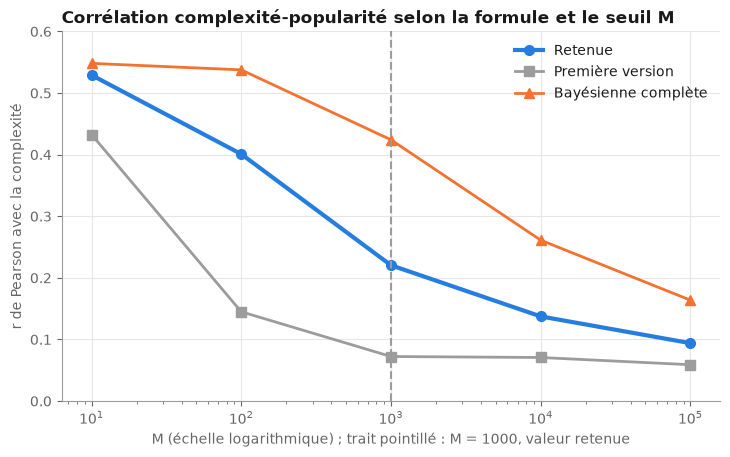

In [265]:
# Sensibilité au seuil M (pour chaque formule) : corrélation de Pearson avec la complexité
appreciation = rating.rank(pct=True)

def popularityFormulas(M):
    notoriety = voters / (voters + M)
    return {
        "Retenue": notoriety * appreciation,
        "Première version": notoriety * rating,
        "Bayésienne complète": notoriety * rating + (1 - notoriety) * globalMean,
    }

rows = []
for M in [10, 100, 1000, 10000, 100000]:
    row = {"M": M}
    for label, popularityM in popularityFormulas(M).items():
        row[label] = stats.pearsonr(cleanedDataFrame[COMPLEXITY], popularityM).statistic
    rows.append(row)
sensitivity = pd.DataFrame(rows).set_index("M")
display(sensitivity.round(3))

#! corrélation avec la complexité selon M et selon la formule
pyplot.figure(figsize=(8.5, 4.8))
styles = {"Retenue": (COLOR_MAIN, "o", 3), "Première version": (COLOR_GREY, "s", 2), "Bayésienne complète": (COLOR_ACCENT, "^", 2)}
for label, (color, marker, width) in styles.items():
    pyplot.plot(sensitivity.index, sensitivity[label], color=color, marker=marker, markersize=7, linewidth=width, label=label)
pyplot.axvline(SIGNIFICATIF_VOTE_NUMBER, color=COLOR_GREY, linestyle="--", linewidth=1.5)
pyplot.xscale("log")
pyplot.ylim(0, 0.6)
pyplot.title("Corrélation complexité-popularité selon la formule et le seuil M")
pyplot.xlabel("M (échelle logarithmique) ; trait pointillé : M = 1000, valeur retenue")
pyplot.ylabel("r de Pearson avec la complexité")
pyplot.legend()
pyplot.show()

**Analyse :**
- **Quelle que soit la formule, la corrélation est positive et significative**, mais son intensité dépend de la part laissée à la notoriété et à l'appréciation : $r = 0{,}07$ avec la première version (qui suit presque uniquement le nombre de votes), $r = 0{,}42$ avec la bayésienne complète (qui suit presque uniquement la note) et $r = 0{,}22$ avec la formule retenue, qui combine les deux. La complexité est liée à l'**appréciation**, pas à la **notoriété** : plus la formule fait de place à la note, plus la corrélation augmente.
- **Sensibilité à $M$** (graphique) : avec la formule retenue, $r$ passe de 0,53 pour $M = 10$ à 0,09 pour $M = 100\,000$. Plus on exige de votes pour être « suffisamment connu », plus la notoriété pèse, et plus la corrélation diminue. Avec $M = 1000$, valeur proche du 3ᵉ quartile du nombre de votants, nous obtenons une valeur intermédiaire. La corrélation reste positive dans tous les cas.

## 7. Interprétation et conclusion

### 7.1 Réponse à la question de départ

**Oui, les jeux plus complexes sont en moyenne plus populaires, mais la corrélation est faible : la complexité explique environ 5 % des différences de popularité.**

| Question | Résultat |
|---|---|
| Corrélation linéaire complexité ~ popularité ? | $r = 0{,}22$ ($\rho = 0{,}26$) ; test de la pente : $T = 25{,}7 > 1{,}96$, $p \approx 10^{-142}$ → **significative** |
| Part de la popularité expliquée par la complexité ? | $R^2 = 4{,}9\,\%$ → **faible** |
| Jeux complexes plus populaires *en moyenne* ? | 0,222 contre 0,148 (Welch : $p \approx 3 \times 10^{-86}$ ; Mann-Whitney : $p \approx 10^{-106}$), $d = 0{,}35$ → **oui, effet petit à moyen** |
| Rôle du type de jeu ? | le type explique ≈ 23 % de la popularité (contre ≈ 5 % pour la complexité) ; à l'intérieur de chaque type, $r$ reste positif (0,08 à 0,45) |
| Complexité et les deux composants de la popularité ? | liée à la **note** ($\rho = 0{,}55$), pas au **nombre de votes** ($\rho = -0{,}01$) |
| Sensibilité à la définition ? | $r = 0{,}07$ (notoriété seule), $0{,}22$ (formule retenue), $0{,}42$ (appréciation seule) |

**Principales découvertes.**
1. Les jeux complexes ne sont **pas plus connus** que les jeux simples (pas de lien avec le nombre de votes), mais ils sont **mieux notés** : c'est cette appréciation plus élevée qui crée le lien avec la popularité.
2. La popularité moyenne **augmente régulièrement** avec la complexité (de 0,11 pour les jeux les plus simples à 0,28 pour les plus complexes), mais la complexité reste un facteur **secondaire**.
3. Ce qui distingue les jeux populaires est d'abord leur **type** (stratégie, famille, thématique) : 23 % de la variance de la popularité, contre 5 % pour la complexité.

### 7.2 Choix de gouvernance (décisions qui découlent du test)

Plaçons-nous du point de vue d'un **éditeur** qui hésite à rendre son prochain jeu plus complexe pour le rendre plus populaire.

- **La complexité n'est pas un frein à la popularité, mais ce n'est pas un levier majeur.** Le test rejette $H_0$ et la relation est positive : à type de jeu égal, un jeu un peu plus complexe n'est pas moins populaire, il l'est plutôt un peu plus. Mais comme $R^2 \approx 5\,\%$, un point de complexité en plus n'apporte en moyenne que 0,06 point de popularité (sur 1) : ce n'est pas une raison suffisante, à elle seule, pour complexifier un jeu.
- **Choisir d'abord le type de jeu et le public visé**, puis ajuster la complexité à ce public : le type explique près de 5 fois plus de variance de la popularité que la complexité.
- **Si l'objectif est la réputation auprès des passionnés** (bonne note, bon classement), la complexité est un levier plus net ($\rho = 0{,}55$ avec la note), mais elle n'élargit pas l'audience (pas de lien avec le nombre de votes).
- **Pour un jury de prix ou un site de recommandation** : un classement par nombre de votes favorise les jeux grand public ; un classement par note favorise les jeux complexes ; une mesure qui combine les deux (comme la nôtre) favorise un peu les jeux complexes sans écraser les autres. Il faut choisir le critère en connaissance de cause.

### 7.3 Limites

- **Corrélation n'est pas causalité.** Nous ne savons pas si la complexité *cause* de meilleures notes ; les joueurs qui votent pour des jeux complexes sont probablement des passionnés qui aiment déjà ce style (biais de sélection).
- **Population restreinte** : jeux de BoardGameGeek avec au moins 30 votants, un « Type 1 » et des durées renseignées (12 963 jeux sur 25 339 ; les jeux écartés sont moins votés et moins complexes). Les votants sont des passionnés, pas des joueurs occasionnels.
- **Popularité définie par nous** : elle dépend de la formule et du seuil $M$ (section 6.7) : $r$ varie de 0,07 à 0,42 selon la formule, et de 0,14 à 0,53 selon $M$ pour la formule retenue. Le rang centile de la note est relatif à notre échantillon. D'autres définitions (ventes, parties jouées) donneraient peut-être d'autres résultats.
- **Mesures subjectives** : la complexité et la note sont des opinions, pas des mesures objectives.
- **Conditions du modèle** : résidus asymétriques (asymétrie ≈ 1,4) et variance non constante (6.4) ; nous avons confirmé par des tests basés sur les rangs (Spearman, Mann-Whitney), mais un modèle plus adapté (transformation, régression robuste) serait préférable.
- **Variables non contrôlées** : un jeu ancien a eu plus de temps pour accumuler des votes (l'année de sortie est disponible dans la base mais n'a pas été utilisée), et nous n'avons retenu que le « Type 1 ».
- **Instantané** : les données représentent une photo à une date donnée, pas une évolution.

**Pistes pour aller plus loin** : régression multiple (popularité expliquée par la complexité, le type et l'année), autre définition de la popularité, prise en compte du « Type 2 ».

## 8. Sources

- **Données** : Vasileios Fotopoulos, *Board Games info from BoardGameGeek.com*, Kaggle — https://www.kaggle.com/datasets/fotopoulosvasileios/board-games-info-from-boardgamegeek-com (fichier `bg_info.csv`). Données issues de BoardGameGeek — https://boardgamegeek.com
- **Moyenne pondérée bayésienne** (formule dont la première version de la popularité est inspirée) : formule utilisée à l'origine par IMDb pour son Top 250, décrite sur https://en.wikipedia.org/wiki/IMDb
- **Méthodes statistiques** : cours d'Outils Statistiques (Henallux-IESN), cours de Modélisation et traitement des données (Henallux-IESN), documentation de `scipy.stats` — https://docs.scipy.org/doc/scipy/reference/stats.html
- **Outils** : Python, pandas, NumPy, SciPy, Matplotlib.